In [ ]:
import pandas as pd
import numpy as np

# Load the cleaned dataset
file_path = "cleaned_supply_chain_dataset.csv"

df = pd.read_csv(file_path)

# Convert date column to datetime
# Dataset stores dates as Day-Month-Year
df["date"] = pd.to_datetime(
    df["date"],
    format="%d-%m-%Y",
    errors="raise"
)

# Aggregate demand to daily network level
daily_demand = (
    df.groupby("date", as_index=False)["units_sold"]
    .sum()
    .rename(columns={"units_sold": "total_units_sold"})
    .sort_values("date")
    .reset_index(drop=True)
)

daily_demand.head()

,date,total_units_sold
0,2024-01-01,5054
1,2024-01-02,5072
2,2024-01-03,5278
3,2024-01-04,5144
4,2024-01-05,5208


In [ ]:
# Validate the structure of the daily time series

print("Number of observations :", len(daily_demand))
print("Earliest date          :", daily_demand["date"].min())
print("Latest date            :", daily_demand["date"].max())
print("Unique dates           :", daily_demand["date"].nunique())

# Check for duplicate dates
duplicate_dates = daily_demand["date"].duplicated().sum()

# Check for missing dates
expected_dates = pd.date_range(
    start=daily_demand["date"].min(),
    end=daily_demand["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(
    daily_demand["date"]
)

print("Duplicate dates        :", duplicate_dates)
print("Missing dates          :", len(missing_dates))

Number of observations : 365
Earliest date          : 2024-01-01 00:00:00
Latest date            : 2024-12-30 00:00:00
Unique dates           : 365
Duplicate dates        : 0
Missing dates          : 0


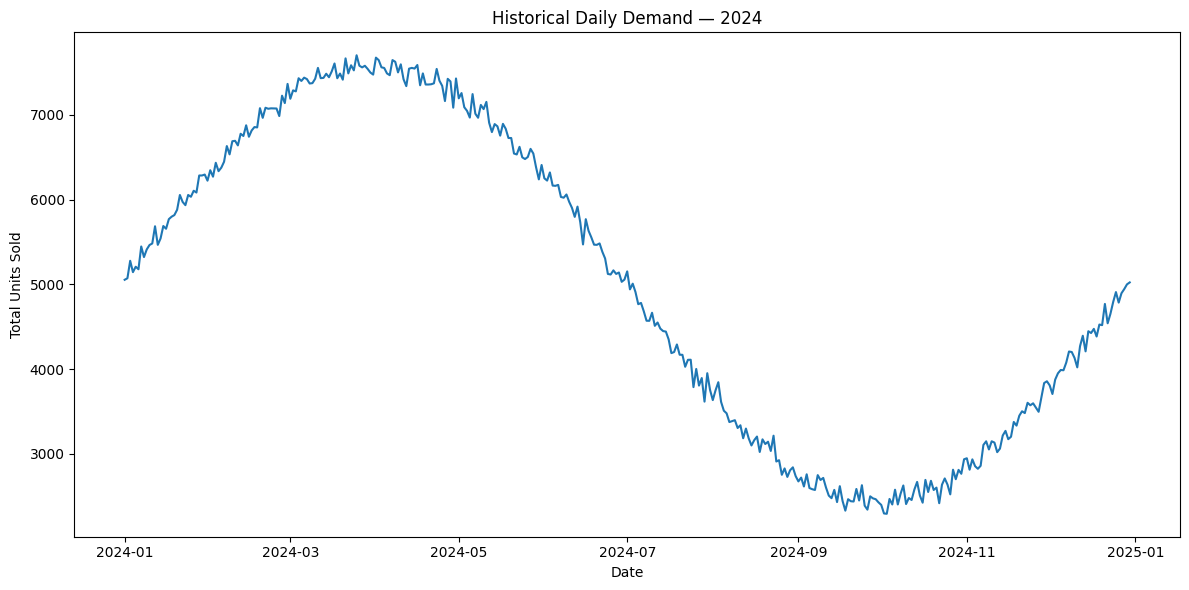

In [ ]:
# Visualize the historical daily demand series

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    daily_demand["date"],
    daily_demand["total_units_sold"]
)

plt.title("Historical Daily Demand — 2024")
plt.xlabel("Date")
plt.ylabel("Total Units Sold")

plt.tight_layout()
plt.show()

In [ ]:
import sys

print("Python executable:")
print(sys.executable)

print("\nInstalling statsmodels...")

Python executable:
d:\Python Udemy\1-Python Basics\venv\python.exe

Installing statsmodels...


In [ ]:
import subprocess
import sys

subprocess.check_call([
    sys.executable,
    "-m",
    "pip",
    "install",
    "statsmodels"
])

0

In [ ]:
import statsmodels

print("statsmodels version:", statsmodels.__version__)

statsmodels version: 0.15.0


In [ ]:
# Decompose daily demand into trend, weekly seasonality, and residual

from statsmodels.tsa.seasonal import STL

# Create a time-indexed demand series
demand_series = (
    daily_demand
    .set_index("date")["total_units_sold"]
)

# Apply STL decomposition with weekly seasonality
stl = STL(
    demand_series,
    period=7,
    robust=True
)

decomposition = stl.fit()

# Store the components separately
trend = decomposition.trend
seasonal = decomposition.seasonal
residual = decomposition.resid

# Display the first few values
print("Trend:")
print(trend.head())

print("\nWeekly seasonal component:")
print(seasonal.head())

print("\nResidual:")
print(residual.head())

Trend:
date
2024-01-01    5079.963649
2024-01-02    5119.574334
2024-01-03    5159.352098
2024-01-04    5199.336522
2024-01-05    5239.493491
Name: trend, dtype: float64

Weekly seasonal component:
date
2024-01-01   -33.053112
2024-01-02   -34.091791
2024-01-03    84.840967
2024-01-04   -37.817300
2024-01-05   -21.286340
Name: season, dtype: float64

Residual:
date
2024-01-01     7.089463
2024-01-02   -13.482543
2024-01-03    33.806935
2024-01-04   -17.519221
2024-01-05   -10.207151
Name: resid, dtype: float64


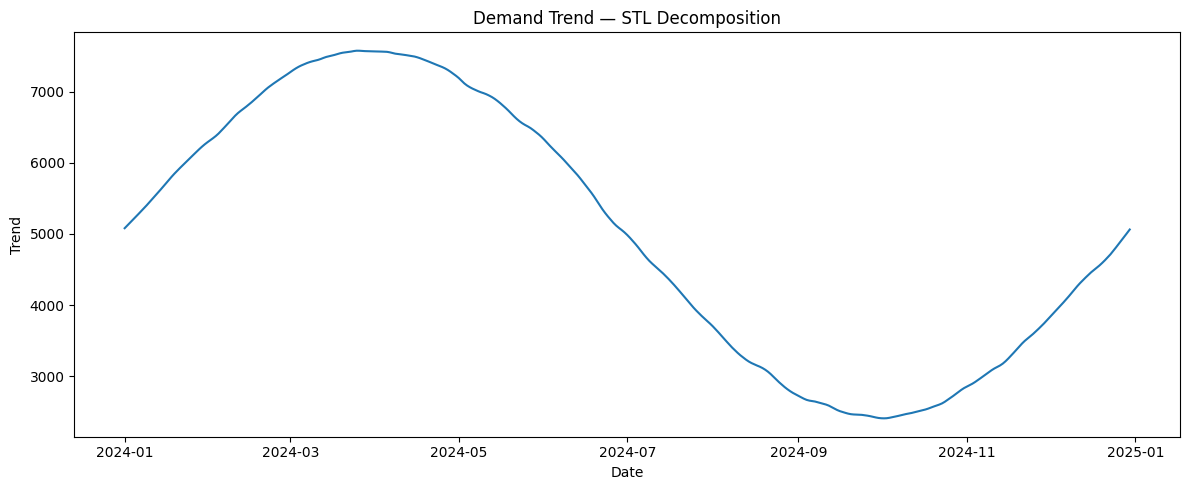

In [ ]:
# Plot the STL trend component

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    trend.index,
    trend
)

plt.title("Demand Trend — STL Decomposition")
plt.xlabel("Date")
plt.ylabel("Trend")

plt.tight_layout()
plt.show()

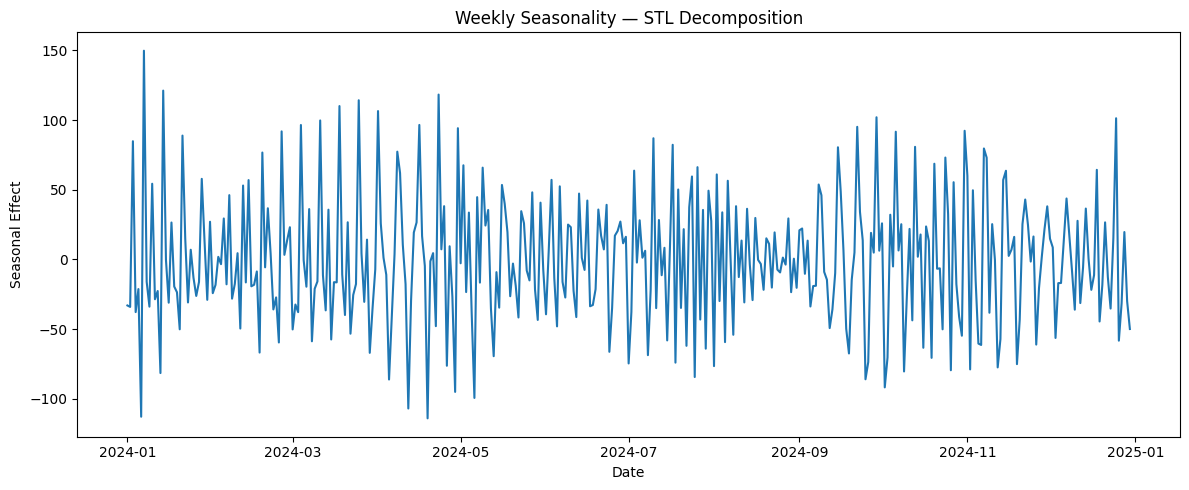

In [ ]:
# Plot the weekly seasonal component

plt.figure(figsize=(12, 5))

plt.plot(
    seasonal.index,
    seasonal
)

plt.title("Weekly Seasonality — STL Decomposition")
plt.xlabel("Date")
plt.ylabel("Seasonal Effect")

plt.tight_layout()
plt.show()

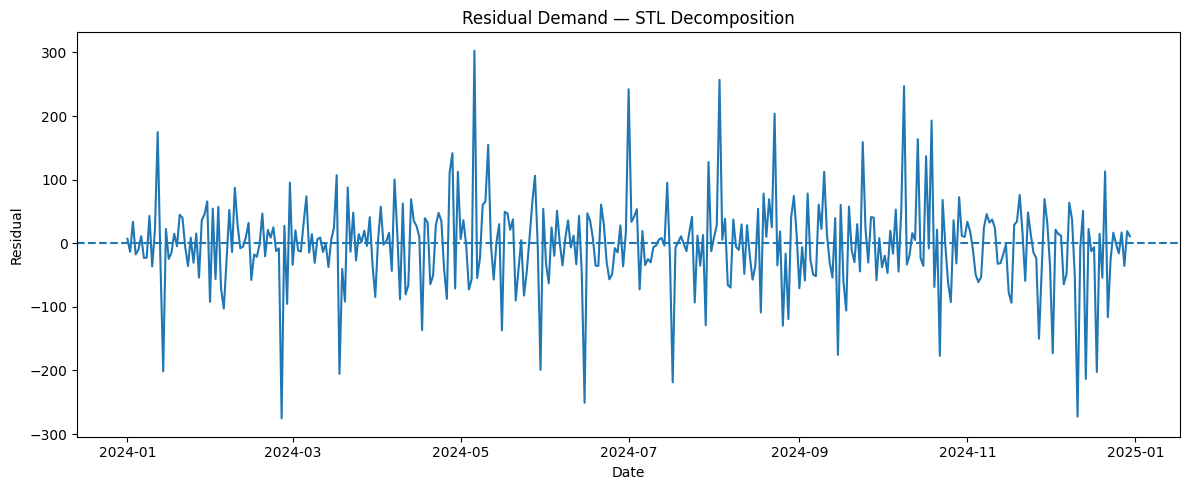

In [ ]:
# Plot the residual component

plt.figure(figsize=(12, 5))

plt.plot(
    residual.index,
    residual
)

plt.axhline(
    0,
    linestyle="--"
)

plt.title("Residual Demand — STL Decomposition")
plt.xlabel("Date")
plt.ylabel("Residual")

plt.tight_layout()
plt.show()

In [ ]:
# Quantify the strength of trend and weekly seasonality

trend_strength = max(
    0,
    1 - (
        np.var(residual)
        / np.var(trend + residual)
    )
)

seasonal_strength = max(
    0,
    1 - (
        np.var(residual)
        / np.var(seasonal + residual)
    )
)

print(f"Trend strength    : {trend_strength:.4f}")
print(f"Seasonal strength : {seasonal_strength:.4f}")

Trend strength    : 0.9984
Seasonal strength : 0.2229


“The 2024 demand series is dominated by a strong smooth trend-like pattern, while the estimated weekly seasonal component is relatively weaker.”

In [ ]:
# Create a chronological train-test split

test_days = 30

train = daily_demand.iloc[:-test_days].copy()
test = daily_demand.iloc[-test_days:].copy()

print("Training observations :", len(train))
print("Test observations     :", len(test))

print("\nTraining period:")
print(train["date"].min(), "to", train["date"].max())

print("\nTest period:")
print(test["date"].min(), "to", test["date"].max())

Training observations : 335
Test observations     : 30

Training period:
2024-01-01 00:00:00 to 2024-11-30 00:00:00

Test period:
2024-12-01 00:00:00 to 2024-12-30 00:00:00


In [ ]:
# Create a naive forecast using the last observed training value

last_train_demand = train["total_units_sold"].iloc[-1]

test["naive_forecast"] = last_train_demand

print("Last observed training demand:", last_train_demand)

test[
    [
        "date",
        "total_units_sold",
        "naive_forecast"
    ]
].head(10)

Last observed training demand: 3857


,date,total_units_sold,naive_forecast
335,2024-12-01,3809,3857
336,2024-12-02,3707,3857
337,2024-12-03,3877,3857
338,2024-12-04,3951,3857
339,2024-12-05,3990,3857
340,2024-12-06,3987,3857
341,2024-12-07,4077,3857
342,2024-12-08,4208,3857
343,2024-12-09,4202,3857
344,2024-12-10,4133,3857


In [ ]:
# Evaluate the naive forecast

actual = test["total_units_sold"]
forecast = test["naive_forecast"]

naive_mae = np.mean(
    np.abs(actual - forecast)
)

naive_rmse = np.sqrt(
    np.mean((actual - forecast) ** 2)
)

naive_wape = (
    np.abs(actual - forecast).sum()
    / actual.sum()
) * 100

print(f"Naive Forecast MAE  : {naive_mae:,.2f} units")
print(f"Naive Forecast RMSE : {naive_rmse:,.2f} units")
print(f"Naive Forecast WAPE : {naive_wape:.2f}%")

Naive Forecast MAE  : 553.70 units
Naive Forecast RMSE : 657.36 units
Naive Forecast WAPE : 12.59%


In [ ]:
# Create a seasonal naive forecast using the last observed 7-day pattern

seasonal_period = 7

last_week_demand = (
    train["total_units_sold"]
    .tail(seasonal_period)
    .to_numpy()
)

seasonal_naive_values = np.tile(
    last_week_demand,
    int(np.ceil(len(test) / seasonal_period))
)[:len(test)]

test["seasonal_naive_forecast"] = seasonal_naive_values

print("Last observed 7-day demand pattern:")
print(last_week_demand)

print("\nSeasonal naive forecast:")
print(
    test[
        [
            "date",
            "total_units_sold",
            "seasonal_naive_forecast"
        ]
    ].head(10)
)

Last observed 7-day demand pattern:
[3574 3597 3547 3497 3667 3836 3857]

Seasonal naive forecast:
          date  total_units_sold  seasonal_naive_forecast
335 2024-12-01              3809                     3574
336 2024-12-02              3707                     3597
337 2024-12-03              3877                     3547
338 2024-12-04              3951                     3497
339 2024-12-05              3990                     3667
340 2024-12-06              3987                     3836
341 2024-12-07              4077                     3857
342 2024-12-08              4208                     3574
343 2024-12-09              4202                     3597
344 2024-12-10              4133                     3547


In [ ]:
# Evaluate the seasonal naive forecast

actual = test["total_units_sold"]
forecast = test["seasonal_naive_forecast"]

seasonal_naive_mae = np.mean(
    np.abs(actual - forecast)
)

seasonal_naive_rmse = np.sqrt(
    np.mean((actual - forecast) ** 2)
)

seasonal_naive_wape = (
    np.abs(actual - forecast).sum()
    / actual.sum()
) * 100

print(
    f"Seasonal Naive MAE  : "
    f"{seasonal_naive_mae:,.2f} units"
)

print(
    f"Seasonal Naive RMSE : "
    f"{seasonal_naive_rmse:,.2f} units"
)

print(
    f"Seasonal Naive WAPE : "
    f"{seasonal_naive_wape:.2f}%"
)

Seasonal Naive MAE  : 748.47 units
Seasonal Naive RMSE : 838.48 units
Seasonal Naive WAPE : 17.02%


## Holt's Linear Trend / Double Exponential Smoothing

Demand is currently around X and Demand is trending upward

        ↓
        
Forecast future demand higher

## Unlike Naive:
Tomorrow = Last observed value

In [ ]:
# Build a Holt linear trend forecasting model

from statsmodels.tsa.holtwinters import Holt

# Create and fit the Holt model
holt_model = Holt(
    train["total_units_sold"],
    initialization_method="estimated"
).fit()

# Forecast the next 30 days
holt_forecast = holt_model.forecast(
    len(test)
)

# Store the forecast
test["holt_forecast"] = holt_forecast.values

# Preview actual vs forecast
test[
    [
        "date",
        "total_units_sold",
        "holt_forecast"
    ]
].head(10)  

,date,total_units_sold,holt_forecast
335,2024-12-01,3809,3808.745386
336,2024-12-02,3707,3847.971789
337,2024-12-03,3877,3887.198193
338,2024-12-04,3951,3926.424596
339,2024-12-05,3990,3965.650999
340,2024-12-06,3987,4004.877403
341,2024-12-07,4077,4044.103806
342,2024-12-08,4208,4083.330210
343,2024-12-09,4202,4122.556613
344,2024-12-10,4133,4161.783016


In [ ]:
# Evaluate the Holt forecast

actual = test["total_units_sold"]
forecast = test["holt_forecast"]

holt_mae = np.mean(
    np.abs(actual - forecast)
)

holt_rmse = np.sqrt(
    np.mean((actual - forecast) ** 2)
)

holt_wape = (
    np.abs(actual - forecast).sum()
    / actual.sum()
) * 100

print(
    f"Holt Forecast MAE  : "
    f"{holt_mae:,.2f} units"
)

print(
    f"Holt Forecast RMSE : "
    f"{holt_rmse:,.2f} units"
)

print(
    f"Holt Forecast WAPE : "
    f"{holt_wape:.2f}%"
)

Holt Forecast MAE  : 68.49 units
Holt Forecast RMSE : 85.54 units
Holt Forecast WAPE : 1.56%


In [ ]:
# Build a Holt model with a damped trend

damped_holt_model = Holt(
    train["total_units_sold"],
    damped_trend=True,
    initialization_method="estimated"
).fit()

# Forecast the next 30 days
damped_holt_forecast = damped_holt_model.forecast(
    len(test)
)

# Store the forecast
test["damped_holt_forecast"] = (
    damped_holt_forecast.values
)

# Preview actual vs forecast
test[
    [
        "date",
        "total_units_sold",
        "holt_forecast",
        "damped_holt_forecast"
    ]
].head(10)

,date,total_units_sold,holt_forecast,damped_holt_forecast
335,2024-12-01,3809,3808.745386,3801.943072
336,2024-12-02,3707,3847.971789,3839.806590
337,2024-12-03,3877,3887.198193,3877.480792
338,2024-12-04,3951,3926.424596,3914.966622
339,2024-12-05,3990,3965.650999,3952.265023
340,2024-12-06,3987,4004.877403,3989.376932
341,2024-12-07,4077,4044.103806,4026.303282
342,2024-12-08,4208,4083.330210,4063.045000
343,2024-12-09,4202,4122.556613,4099.603009
344,2024-12-10,4133,4161.783016,4135.978228


In [ ]:

# Evaluate the Damped Holt forecast

actual = test["total_units_sold"]
forecast = test["damped_holt_forecast"]

damped_holt_mae = np.mean(
    np.abs(actual - forecast)
)

damped_holt_rmse = np.sqrt(
    np.mean((actual - forecast) ** 2)
)

damped_holt_wape = (
    np.abs(actual - forecast).sum()
    / actual.sum()
) * 100

print(
    f"Damped Holt MAE  : "
    f"{damped_holt_mae:,.2f} units"
)

print(
    f"Damped Holt RMSE : "
    f"{damped_holt_rmse:,.2f} units"
)

print(
    f"Damped Holt WAPE : "
    f"{damped_holt_wape:.2f}%"
)

Damped Holt MAE  : 98.82 units
Damped Holt RMSE : 122.63 units
Damped Holt WAPE : 2.25%


In [ ]:
# Update the model comparison table with Damped Holt

model_comparison = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "Holt",
        "Damped Holt"
    ],
    "MAE": [
        naive_mae,
        seasonal_naive_mae,
        holt_mae,
        damped_holt_mae
    ],
    "RMSE": [
        naive_rmse,
        seasonal_naive_rmse,
        holt_rmse,
        damped_holt_rmse
    ],
    "WAPE": [
        naive_wape,
        seasonal_naive_wape,
        holt_wape,
        damped_holt_wape
    ]
})

model_comparison = (
    model_comparison
    .sort_values("WAPE")
    .reset_index(drop=True)
)

model_comparison

,Model,MAE,RMSE,WAPE
0,Holt,68.491854,85.543745,1.557518
1,Damped Holt,98.817078,122.630737,2.247119
2,Naive,553.700000,657.364207,12.591245
3,Seasonal Naive,748.466667,838.483433,17.020277


In [ ]:
# Build a Holt-Winters model with trend and weekly seasonality

from statsmodels.tsa.holtwinters import ExponentialSmoothing

hw_model = ExponentialSmoothing(
    train["total_units_sold"],
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit()

# Forecast the next 30 days
hw_forecast = hw_model.forecast(
    len(test)
)

# Store the forecast
test["holt_winters_forecast"] = hw_forecast.values

# Preview actual vs forecast
test[
    [
        "date",
        "total_units_sold",
        "holt_forecast",
        "holt_winters_forecast"
    ]
].head(10)

,date,total_units_sold,holt_forecast,holt_winters_forecast
335,2024-12-01,3809,3808.745386,3823.991861
336,2024-12-02,3707,3847.971789,3859.152259
337,2024-12-03,3877,3887.198193,3893.034906
338,2024-12-04,3951,3926.424596,3916.299103
339,2024-12-05,3990,3965.650999,3966.121936
340,2024-12-06,3987,4004.877403,4014.074082
341,2024-12-07,4077,4044.103806,4037.030009
342,2024-12-08,4208,4083.330210,4101.000254
343,2024-12-09,4202,4122.556613,4136.160651
344,2024-12-10,4133,4161.783016,4170.043298


Naive
   → level only

Seasonal Naive
   → weekly pattern only

Holt
   → level + trend

Damped Holt
   → level + damped trend

Holt-Winters
   → level + trend + weekly seasonality

In [ ]:
# Evaluate the Holt-Winters forecast

actual = test["total_units_sold"]
forecast = test["holt_winters_forecast"]

holt_winters_mae = np.mean(
    np.abs(actual - forecast)
)

holt_winters_rmse = np.sqrt(
    np.mean((actual - forecast) ** 2)
)

holt_winters_wape = (
    np.abs(actual - forecast).sum()
    / actual.sum()
) * 100

print(
    f"Holt-Winters MAE  : "
    f"{holt_winters_mae:,.2f} units"
)

print(
    f"Holt-Winters RMSE : "
    f"{holt_winters_rmse:,.2f} units"
)

print(
    f"Holt-Winters WAPE : "
    f"{holt_winters_wape:.2f}%"
)

Holt-Winters MAE  : 66.58 units
Holt-Winters RMSE : 82.71 units
Holt-Winters WAPE : 1.51%


The demand series is primarily driven by its smooth trend, while weekly seasonality provides a smaller additional forecasting signal.

## Rolling Time-Series Backtesting

Historical data
      ↓
Train
      ↓
Forecast next 30 days
      ↓
Evaluate

Move forward
      ↓
Train on more data
      ↓
Forecast next 30 days
      ↓
Evaluate

Repeat...

In [ ]:
# Create rolling time-series backtesting windows

forecast_horizon = 30
number_of_folds = 4

backtest_windows = []

for fold in range(number_of_folds):
    
    test_end = len(daily_demand) - (
        (number_of_folds - 1 - fold) * forecast_horizon
    )
    
    test_start = test_end - forecast_horizon
    train_end = test_start
    
    backtest_windows.append({
        "fold": fold + 1,
        "train_start": daily_demand["date"].iloc[0],
        "train_end": daily_demand["date"].iloc[train_end - 1],
        "test_start": daily_demand["date"].iloc[test_start],
        "test_end": daily_demand["date"].iloc[test_end - 1]
    })

backtest_windows_df = pd.DataFrame(backtest_windows)

backtest_windows_df

,fold,train_start,train_end,test_start,test_end
0,1,2024-01-01,2024-09-01,2024-09-02,2024-10-01
1,2,2024-01-01,2024-10-01,2024-10-02,2024-10-31
2,3,2024-01-01,2024-10-31,2024-11-01,2024-11-30
3,4,2024-01-01,2024-11-30,2024-12-01,2024-12-30


In [ ]:
from statsmodels.tsa.holtwinters import Holt, ExponentialSmoothing

# Store results from every fold and every model
backtest_results = []

forecast_horizon = 30

for _, window in backtest_windows_df.iterrows():

    # Get train and test dates for this fold
    train_end = window["train_end"]
    test_start = window["test_start"]
    test_end = window["test_end"]

    # Create fold-specific training and test datasets
    fold_train = daily_demand[
        daily_demand["date"] <= train_end
    ].copy()

    fold_test = daily_demand[
        (daily_demand["date"] >= test_start) &
        (daily_demand["date"] <= test_end)
    ].copy()

    actual = fold_test["total_units_sold"]

    # --------------------------------------------------
    # 1. Naive Forecast
    # --------------------------------------------------

    naive_forecast = np.repeat(
        fold_train["total_units_sold"].iloc[-1],
        len(fold_test)
    )

    # --------------------------------------------------
    # 2. Seasonal Naive Forecast
    # --------------------------------------------------

    last_week = (
        fold_train["total_units_sold"]
        .tail(7)
        .to_numpy()
    )

    seasonal_naive_forecast = np.tile(
        last_week,
        int(np.ceil(len(fold_test) / 7))
    )[:len(fold_test)]

    # --------------------------------------------------
    # 3. Holt Forecast
    # --------------------------------------------------

    holt_model = Holt(
        fold_train["total_units_sold"],
        initialization_method="estimated"
    ).fit()

    holt_forecast = holt_model.forecast(
        len(fold_test)
    ).to_numpy()

    # --------------------------------------------------
    # 4. Damped Holt Forecast
    # --------------------------------------------------

    damped_holt_model = Holt(
        fold_train["total_units_sold"],
        damped_trend=True,
        initialization_method="estimated"
    ).fit()

    damped_holt_forecast = (
        damped_holt_model
        .forecast(len(fold_test))
        .to_numpy()
    )

    # --------------------------------------------------
    # 5. Holt-Winters Forecast
    # --------------------------------------------------

    hw_model = ExponentialSmoothing(
        fold_train["total_units_sold"],
        trend="add",
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    ).fit()

    hw_forecast = (
        hw_model
        .forecast(len(fold_test))
        .to_numpy()
    )

    # --------------------------------------------------
    # Store forecasts
    # --------------------------------------------------

    forecasts = {
        "Naive": naive_forecast,
        "Seasonal Naive": seasonal_naive_forecast,
        "Holt": holt_forecast,
        "Damped Holt": damped_holt_forecast,
        "Holt-Winters": hw_forecast
    }

    # --------------------------------------------------
    # Calculate metrics for each model
    # --------------------------------------------------

    for model_name, forecast in forecasts.items():

        mae = np.mean(
            np.abs(actual.to_numpy() - forecast)
        )

        rmse = np.sqrt(
            np.mean(
                (actual.to_numpy() - forecast) ** 2
            )
        )

        wape = (
            np.abs(
                actual.to_numpy() - forecast
            ).sum()
            / actual.sum()
        ) * 100

        backtest_results.append({
            "fold": int(window["fold"]),
            "model": model_name,
            "mae": mae,
            "rmse": rmse,
            "wape": wape
        })

# Convert results into a DataFrame
backtest_results_df = pd.DataFrame(
    backtest_results
)

backtest_results_df.head(20)

,fold,model,mae,rmse,wape
0,1,Naive,159.166667,184.702554,6.280663
1,1,Seasonal Naive,242.466667,271.552082,9.567654
2,1,Holt,278.897780,335.500062,11.005213
3,1,Damped Holt,241.275183,290.952971,9.520638
4,1,Holt-Winters,275.882397,331.120218,10.886227
5,2,Naive,188.066667,231.359749,7.308290
6,2,Seasonal Naive,169.033333,222.321914,6.568653
7,2,Holt,217.896255,266.587290,8.467471
8,2,Damped Holt,214.394245,262.391011,8.331383
9,2,Holt-Winters,225.986292,275.692892,8.781851


In [ ]:
# Calculate average performance across all backtesting folds

average_backtest_metrics = (
    backtest_results_df
    .groupby("model")
    .agg(
        average_mae=("mae", "mean"),
        average_rmse=("rmse", "mean"),
        average_wape=("wape", "mean")
    )
    .reset_index()
    .sort_values("average_wape")
    .reset_index(drop=True)
)

average_backtest_metrics

,model,average_mae,average_rmse,average_wape
0,Damped Holt,188.889634,230.223764,6.561955
1,Holt,184.132680,223.921003,6.566695
2,Holt-Winters,184.869229,224.395113,6.603019
3,Naive,315.108333,379.623751,9.293381
4,Seasonal Naive,424.791667,490.429196,12.411260


In [ ]:
# Measure forecasting stability across backtesting folds

backtest_stability = (
    backtest_results_df
    .groupby("model")
    .agg(
        average_mae=("mae", "mean"),
        std_mae=("mae", "std"),
        average_rmse=("rmse", "mean"),
        std_rmse=("rmse", "std"),
        average_wape=("wape", "mean"),
        std_wape=("wape", "std"),
        minimum_wape=("wape", "min"),
        maximum_wape=("wape", "max")
    )
    .reset_index()
    .sort_values("average_wape")
    .reset_index(drop=True)
)

backtest_stability

,model,average_mae,std_mae,average_rmse,std_rmse,average_wape,std_wape,minimum_wape,maximum_wape
0,Damped Holt,188.889634,62.332996,230.223764,74.195726,6.561955,3.197566,2.247119,9.520638
1,Holt,184.132680,88.805594,223.921003,105.940801,6.566695,4.089599,1.557518,11.005213
2,Holt-Winters,184.869229,89.736500,224.395113,107.025661,6.603019,4.118097,1.514043,10.886227
3,Naive,315.108333,181.983508,379.623751,217.101561,9.293381,2.987907,6.280663,12.591245
4,Seasonal Naive,424.791667,268.644439,490.429196,294.523370,12.411260,5.166840,6.568653,17.020277


“Rolling-origin backtesting across four 30-day validation windows showed that the trend-based exponential-smoothing models substantially outperformed the Naive baselines. Damped Holt produced the lowest average WAPE (6.56%) and the lowest WAPE variability, while regular Holt achieved slightly lower average MAE and RMSE. Because the WAPE difference was negligible, Damped Holt was retained as the final forecasting candidate based on its slightly better average WAPE and greater stability.”

In [ ]:
# Train the final Damped Holt model on all available historical demand

final_damped_holt_model = Holt(
    daily_demand["total_units_sold"],
    damped_trend=True,
    initialization_method="estimated"
).fit()

# Forecast the next 30 days
forecast_horizon = 30

future_forecast = (
    final_damped_holt_model
    .forecast(forecast_horizon)
)

# Create future dates
future_dates = pd.date_range(
    start=daily_demand["date"].max() + pd.Timedelta(days=1),
    periods=forecast_horizon,
    freq="D"
)

# Create the final forecast table
final_forecast = pd.DataFrame({
    "date": future_dates,
    "forecast_demand": future_forecast.values
})

final_forecast.head(30)

,date,forecast_demand
0,2024-12-31,5054.572111
1,2025-01-01,5098.223342
2,2025-01-02,5141.656316
3,2025-01-03,5184.872126
4,2025-01-04,5227.871857
5,2025-01-05,5270.656589
6,2025-01-06,5313.227398
7,2025-01-07,5355.585353
8,2025-01-08,5397.731517
9,2025-01-09,5439.666951


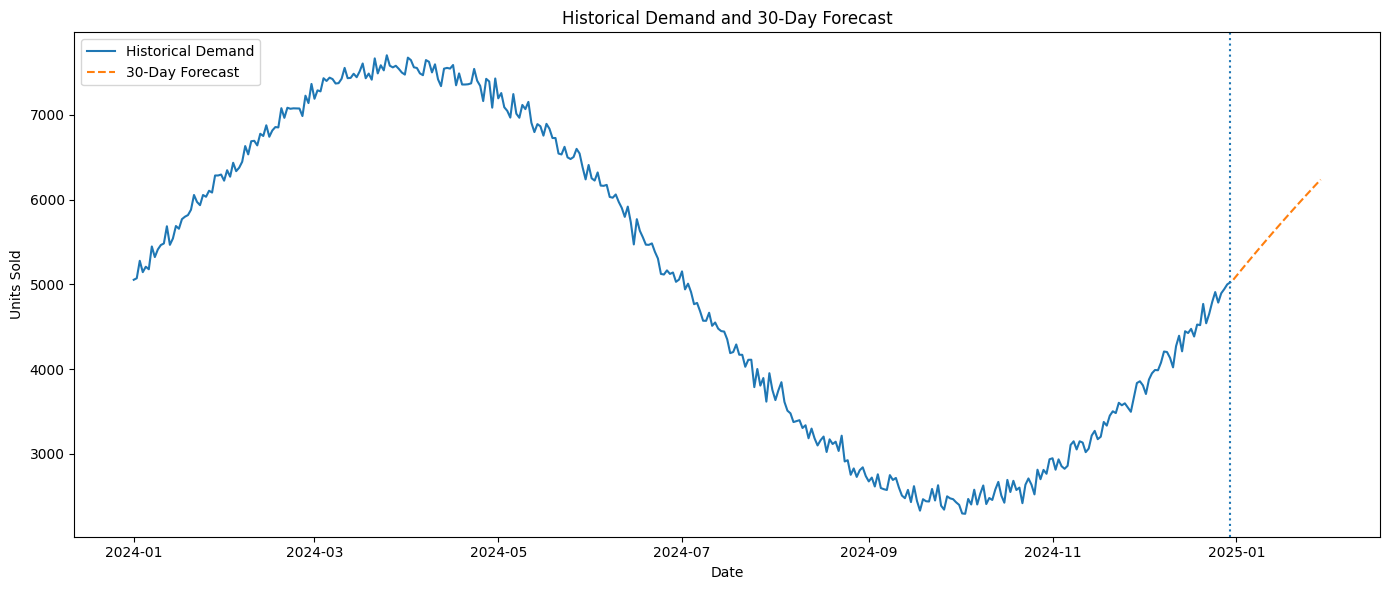

In [ ]:
# Visualize historical demand and the 30-day future forecast

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Historical demand
plt.plot(
    daily_demand["date"],
    daily_demand["total_units_sold"],
    label="Historical Demand"
)

# Forecast demand
plt.plot(
    final_forecast["date"],
    final_forecast["forecast_demand"],
    linestyle="--",
    label="30-Day Forecast"
)

# Mark the start of the forecast period
plt.axvline(
    daily_demand["date"].max(),
    linestyle=":"
)

plt.title("Historical Demand and 30-Day Forecast")
plt.xlabel("Date")
plt.ylabel("Units Sold")

plt.legend()

plt.tight_layout()
plt.show()

“Four rolling 30-day backtests showed that trend-based exponential smoothing substantially outperformed the Naive baselines. Damped Holt produced the lowest average WAPE at 6.56% and the lowest WAPE variability, while Holt had slightly lower average MAE and RMSE. The difference between the two was very small, so Damped Holt was retained as the final forecasting candidate based primarily on consistency.”

In [ ]:
# Validate the SKU-Warehouse time series structure

sku_warehouse_summary = (
    df.groupby(["sku_id", "warehouse_id"])
    .agg(
        observation_count=("date", "nunique"),
        start_date=("date", "min"),
        end_date=("date", "max")
    )
    .reset_index()
)

print(
    "Number of SKU-Warehouse combinations:",
    len(sku_warehouse_summary)
)

print(
    "Expected combinations:",
    df["sku_id"].nunique() *
    df["warehouse_id"].nunique()
)

print(
    "\nObservation count statistics:"
)

print(
    sku_warehouse_summary["observation_count"]
    .describe()
)

print(
    "\nCombinations with fewer than 365 observations:",
    (
        sku_warehouse_summary["observation_count"] < 365
    ).sum()
)

print(
    "\nCombinations with more than 365 observations:",
    (
        sku_warehouse_summary["observation_count"] > 365
    ).sum()
)

Number of SKU-Warehouse combinations: 250
Expected combinations: 250

Observation count statistics:
count    250.0
mean     365.0
std        0.0
min      365.0
25%      365.0
50%      365.0
75%      365.0
max      365.0
Name: observation_count, dtype: float64

Combinations with fewer than 365 observations: 0

Combinations with more than 365 observations: 0


In [ ]:

# Step 4.7.2 — Prepare SKU-Warehouse daily demand

# 1. Check duplicate records at the expected grain
duplicate_records = df.duplicated(
    subset=["date", "sku_id", "warehouse_id"]
).sum()

print("Duplicate SKU-Warehouse-Date records:", duplicate_records)

# 2. Aggregate units sold at SKU-Warehouse-Date level
sku_warehouse_daily = (
    df.groupby(
        ["date", "sku_id", "warehouse_id"],
        as_index=False
    )["units_sold"]
    .sum()
    .rename(columns={"units_sold": "daily_demand"})
    .sort_values(["sku_id", "warehouse_id", "date"])
    .reset_index(drop=True)
)

# 3. Display dataset size
print("Total rows:", len(sku_warehouse_daily))
print("Unique SKUs:", sku_warehouse_daily["sku_id"].nunique())
print("Unique warehouses:", sku_warehouse_daily["warehouse_id"].nunique())

print(
    "Unique SKU-Warehouse combinations:",
    sku_warehouse_daily[["sku_id", "warehouse_id"]]
    .drop_duplicates()
    .shape[0]
)

# 4. Preview the result
sku_warehouse_daily.head(10)


Duplicate SKU-Warehouse-Date records: 0
Total rows: 91250
Unique SKUs: 50
Unique warehouses: 5
Unique SKU-Warehouse combinations: 250


,date,sku_id,warehouse_id,daily_demand
0,2024-01-01,SKU_1,WH_1,10
1,2024-01-02,SKU_1,WH_1,17
2,2024-01-03,SKU_1,WH_1,35
3,2024-01-04,SKU_1,WH_1,24
4,2024-01-05,SKU_1,WH_1,21
5,2024-01-06,SKU_1,WH_1,18
6,2024-01-07,SKU_1,WH_1,19
7,2024-01-08,SKU_1,WH_1,23
8,2024-01-09,SKU_1,WH_1,25
9,2024-01-10,SKU_1,WH_1,25


In [ ]:
# Calculate demand statistics for each SKU and warehouse

sku_demand_summary = (
    sku_warehouse_daily
    .groupby(["sku_id", "warehouse_id"])["daily_demand"]
    .agg(
        total_demand="sum",
        average_daily_demand="mean",
        minimum_demand="min",
        maximum_demand="max",
        demand_std="std"
    )
    .reset_index()
)

# Round numerical values for readability
numeric_columns = [
    "average_daily_demand",
    "demand_std"
]

sku_demand_summary[numeric_columns] = (
    sku_demand_summary[numeric_columns].round(2)
)

# Preview the results
sku_demand_summary.head(10)

,sku_id,warehouse_id,total_demand,average_daily_demand,minimum_demand,maximum_demand,demand_std
0,SKU_1,WH_1,7472,20.47,0,50,8.93
1,SKU_1,WH_2,7299,20.00,0,52,8.91
2,SKU_1,WH_3,7361,20.17,0,46,9.12
3,SKU_1,WH_4,7449,20.41,0,42,8.80
4,SKU_1,WH_5,7445,20.40,0,49,9.01
5,SKU_10,WH_1,7307,20.02,0,52,9.16
6,SKU_10,WH_2,7220,19.78,0,53,9.01
7,SKU_10,WH_3,7279,19.94,0,49,9.20
8,SKU_10,WH_4,7376,20.21,0,47,9.15
9,SKU_10,WH_5,7397,20.27,0,45,8.85


In [ ]:
## Create a train-test split for every SKU-Warehouse combination
# Step 1: Sort the data chronologically

sku_warehouse_daily = sku_warehouse_daily.sort_values(
    ["sku_id", "warehouse_id", "date"]
).copy()

# Number of days reserved for testing
test_days = 30

# Create empty lists to store each combination's data
train_parts = []
test_parts = []

# Split each SKU-Warehouse combination separately
for (sku, warehouse), group in sku_warehouse_daily.groupby(
    ["sku_id", "warehouse_id"]
):
    group = group.sort_values("date")

    # First 335 days: training data
    train_parts.append(group.iloc[:-test_days])

    # Last 30 days: testing data
    test_parts.append(group.iloc[-test_days:])

# Combine all groups into two DataFrames
sku_train = pd.concat(train_parts, ignore_index=True)
sku_test = pd.concat(test_parts, ignore_index=True)

# Display the results
print("Training rows:", len(sku_train))
print("Testing rows:", len(sku_test))

print("\nTraining date range:")
print(sku_train["date"].min(), "to", sku_train["date"].max())

print("\nTesting date range:")
print(sku_test["date"].min(), "to", sku_test["date"].max())


Training rows: 83750
Testing rows: 7500

Training date range:
2024-01-01 00:00:00 to 2024-11-30 00:00:00

Testing date range:
2024-12-01 00:00:00 to 2024-12-30 00:00:00


In [ ]:

# Create a summary of demand patterns for each SKU-Warehouse combination

sku_demand_profile = (
    sku_train
    .groupby(["sku_id", "warehouse_id"])["daily_demand"]
    .agg(
        average_demand="mean",
        demand_std="std",
        minimum_demand="min",
        maximum_demand="max",
        zero_demand_days=lambda x: (x == 0).sum()
    )
    .reset_index()
)

# Calculate demand variability relative to average demand
sku_demand_profile["coefficient_of_variation"] = (
    sku_demand_profile["demand_std"]
    / sku_demand_profile["average_demand"].replace(0, np.nan)
)

# Preview the results
print("Number of SKU-Warehouse combinations:",
      len(sku_demand_profile))

sku_demand_profile.head(10)


Number of SKU-Warehouse combinations: 250


,sku_id,warehouse_id,average_demand,demand_std,minimum_demand,maximum_demand,zero_demand_days,coefficient_of_variation
0,SKU_1,WH_1,20.785075,9.125624,0,50,1,0.439047
1,SKU_1,WH_2,20.235821,9.107207,0,52,5,0.450054
2,SKU_1,WH_3,20.367164,9.396113,0,46,3,0.461336
3,SKU_1,WH_4,20.594030,8.995473,0,42,1,0.436800
4,SKU_1,WH_5,20.549254,9.212875,0,49,2,0.448331
5,SKU_10,WH_1,20.289552,9.411567,0,52,2,0.463863
6,SKU_10,WH_2,20.014925,9.282481,0,53,2,0.463778
7,SKU_10,WH_3,19.937313,9.446934,0,49,3,0.473832
8,SKU_10,WH_4,20.426866,9.335714,0,47,1,0.457031
9,SKU_10,WH_5,20.373134,9.100957,0,45,3,0.446714


In [ ]:

# Step 1: Calculate the last observed demand for each SKU-warehouse pair

last_demand = (
    sku_train
    .sort_values("date")
    .groupby(["sku_id", "warehouse_id"])["daily_demand"]
    .last()
    .reset_index(name="last_observed_demand")
)

# Step 2: Remove columns left over from the previous attempt
sku_test = sku_test.drop(
    columns=["last_observed_demand", "naive_forecast"],
    errors="ignore"
)

# Step 3: Merge the last observed demand into the test data
sku_test = sku_test.merge(
    last_demand,
    on=["sku_id", "warehouse_id"],
    how="left",
    validate="many_to_one"
)

# Step 4: Generate the Naive Forecast
sku_test["naive_forecast"] = sku_test["last_observed_demand"]

# Step 5: Preview the output
sku_test[
    [
        "date",
        "sku_id",
        "warehouse_id",
        "daily_demand",
        "last_observed_demand",
        "naive_forecast"
    ]
].head(10)


,date,sku_id,warehouse_id,daily_demand,last_observed_demand,naive_forecast
0,2024-12-01,SKU_1,WH_1,26,4,4
1,2024-12-02,SKU_1,WH_1,13,4,4
2,2024-12-03,SKU_1,WH_1,18,4,4
3,2024-12-04,SKU_1,WH_1,17,4,4
4,2024-12-05,SKU_1,WH_1,13,4,4
5,2024-12-06,SKU_1,WH_1,19,4,4
6,2024-12-07,SKU_1,WH_1,13,4,4
7,2024-12-08,SKU_1,WH_1,13,4,4
8,2024-12-09,SKU_1,WH_1,26,4,4
9,2024-12-10,SKU_1,WH_1,27,4,4


In [ ]:
# Calculate forecast errors

sku_test["absolute_error"] = (
    sku_test["daily_demand"] - sku_test["naive_forecast"]
).abs()

sku_test["squared_error"] = (
    sku_test["daily_demand"] - sku_test["naive_forecast"]
) ** 2

# Calculate evaluation metrics

mae = sku_test["absolute_error"].mean()

rmse = np.sqrt(sku_test["squared_error"].mean())

wape = (
    sku_test["absolute_error"].sum()
    / sku_test["daily_demand"].sum()
) * 100

# Display results

print(f"Naive Forecast MAE  : {mae:.2f} units")
print(f"Naive Forecast RMSE : {rmse:.2f} units")
print(f"Naive Forecast WAPE : {wape:.2f}%")

Naive Forecast MAE  : 6.40 units
Naive Forecast RMSE : 8.09 units
Naive Forecast WAPE : 36.41%


In [ ]:

# Step 1: Sort training data chronologically

sku_train = sku_train.sort_values("date").copy()

# Step 2: Build the historical 7-day demand pattern
weekly_pattern = (
    sku_train
    .sort_values("date")
    .groupby(["sku_id", "warehouse_id"])
    .tail(7)
    .groupby(["sku_id", "warehouse_id"])["daily_demand"]
    .apply(list)
    .reset_index(name="weekly_pattern")
)

# Step 3: Attach the 7-day pattern to test data
sku_seasonal_test = sku_test[
    ["date", "sku_id", "warehouse_id", "daily_demand"]
].copy()

sku_seasonal_test = sku_seasonal_test.merge(
    weekly_pattern,
    on=["sku_id", "warehouse_id"],
    how="left",
    validate="many_to_one"
)

# Step 4: Generate a repeating 7-day forecast
sku_seasonal_test["day_number"] = (
    sku_seasonal_test
    .groupby(["sku_id", "warehouse_id"])
    .cumcount()
)

sku_seasonal_test["seasonal_naive_forecast"] = (
    sku_seasonal_test
    .apply(
        lambda row: row["weekly_pattern"][row["day_number"] % 7],
        axis=1
    )
)

# Step 5: Preview the results
sku_seasonal_test[
    [
        "date",
        "sku_id",
        "warehouse_id",
        "daily_demand",
        "seasonal_naive_forecast"
    ]
].head(10)

,date,sku_id,warehouse_id,daily_demand,seasonal_naive_forecast
0,2024-12-01,SKU_1,WH_1,26,19
1,2024-12-02,SKU_1,WH_1,13,13
2,2024-12-03,SKU_1,WH_1,18,20
3,2024-12-04,SKU_1,WH_1,17,19
4,2024-12-05,SKU_1,WH_1,13,12
5,2024-12-06,SKU_1,WH_1,19,17
6,2024-12-07,SKU_1,WH_1,13,4
7,2024-12-08,SKU_1,WH_1,13,19
8,2024-12-09,SKU_1,WH_1,26,13
9,2024-12-10,SKU_1,WH_1,27,20


In [ ]:
## Calculate Seasonal Naive accuracy

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Step 1: Get actual and forecast values
actual = sku_seasonal_test["daily_demand"]
predicted = sku_seasonal_test["seasonal_naive_forecast"]

# Step 2: Calculate MAE
seasonal_mae = mean_absolute_error(actual, predicted)

# Step 3: Calculate RMSE
seasonal_rmse = np.sqrt(mean_squared_error(actual, predicted))

# Step 4: Calculate WAPE
seasonal_wape = (
    np.abs(actual - predicted).sum() / actual.sum()
) * 100

# Step 5: Display results
print(f"Seasonal Naive MAE  : {seasonal_mae:.2f} units")
print(f"Seasonal Naive RMSE : {seasonal_rmse:.2f} units")
print(f"Seasonal Naive WAPE : {seasonal_wape:.2f}%")

Seasonal Naive MAE  : 6.56 units
Seasonal Naive RMSE : 8.25 units
Seasonal Naive WAPE : 37.27%


In [ ]:
## Holt Forecast at SKU–Warehouse Level

# Step 1: Store forecast results
holt_results = []

# Step 2: Process each SKU-Warehouse combination
for (sku, warehouse), train_group in sku_train.groupby(
    ["sku_id", "warehouse_id"]
):
    # Sort training data by date
    train_group = train_group.sort_values("date")

    # Get matching test data
    test_group = sku_test[
        (sku_test["sku_id"] == sku) &
        (sku_test["warehouse_id"] == warehouse)
    ].sort_values("date")

    # Skip combinations without training or test data
    if train_group.empty or test_group.empty:
        continue

    # Step 3: Fit Holt model
    model = Holt(
        train_group["daily_demand"].astype(float).to_numpy(),
        initialization_method="estimated"
    ).fit(optimized=True)

    # Step 4: Generate forecasts
    forecast = model.forecast(len(test_group))

    # Step 5: Save actual and forecast values
    result = test_group[
        ["date", "sku_id", "warehouse_id", "daily_demand"]
    ].copy()

    result["holt_forecast"] = np.asarray(forecast)
    holt_results.append(result)

# Step 6: Combine results
sku_holt_test = pd.concat(holt_results, ignore_index=True)

# Step 7: Preview and validate
print("Total forecast rows:", len(sku_holt_test))
print("Unique SKU-Warehouse combinations:",
      sku_holt_test.groupby(["sku_id", "warehouse_id"]).ngroups)

sku_holt_test.head(10)

Total forecast rows: 7500
Unique SKU-Warehouse combinations: 250


,date,sku_id,warehouse_id,daily_demand,holt_forecast
0,2024-12-01,SKU_1,WH_1,26,16.228353
1,2024-12-02,SKU_1,WH_1,13,16.328085
2,2024-12-03,SKU_1,WH_1,18,16.427816
3,2024-12-04,SKU_1,WH_1,17,16.527548
4,2024-12-05,SKU_1,WH_1,13,16.627280
5,2024-12-06,SKU_1,WH_1,19,16.727012
6,2024-12-07,SKU_1,WH_1,13,16.826744
7,2024-12-08,SKU_1,WH_1,13,16.926476
8,2024-12-09,SKU_1,WH_1,26,17.026207
9,2024-12-10,SKU_1,WH_1,27,17.125939


In [ ]:
# Calculate Holt forecast accuracy

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Step 1: Get actual and forecast values
actual = sku_holt_test["daily_demand"]
predicted = sku_holt_test["holt_forecast"]

# Step 2: Calculate MAE
holt_mae = mean_absolute_error(actual, predicted)

# Step 3: Calculate RMSE
holt_rmse = np.sqrt(mean_squared_error(actual, predicted))

# Step 4: Calculate WAPE
holt_wape = (
    np.abs(actual - predicted).sum() / actual.sum()
) * 100

# Step 5: Display results
print(f"Holt MAE  : {holt_mae:.2f} units")
print(f"Holt RMSE : {holt_rmse:.2f} units")
print(f"Holt WAPE : {holt_wape:.2f}%")

Holt MAE  : 4.67 units
Holt RMSE : 5.95 units
Holt WAPE : 26.52%


In [ ]:
## Damped Holt forecasts

from statsmodels.tsa.holtwinters import Holt
import pandas as pd
import numpy as np

# Step 1: Store forecast results
damped_holt_results = []

# Step 2: Process each SKU-Warehouse combination
for (sku, warehouse), train_group in sku_train.groupby(
    ["sku_id", "warehouse_id"]
):
    train_group = train_group.sort_values("date")

    # Get matching test data
    test_group = sku_test[
        (sku_test["sku_id"] == sku) &
        (sku_test["warehouse_id"] == warehouse)
    ].sort_values("date")

    if train_group.empty or test_group.empty:
        continue

    # Step 3: Fit Damped Holt model
    model = Holt(
        train_group["daily_demand"].astype(float).to_numpy(),
        damped_trend=True,
        initialization_method="estimated"
    ).fit(optimized=True)

    # Step 4: Generate forecasts
    forecast = model.forecast(len(test_group))

    # Step 5: Store actual and forecast values
    result = test_group[
        ["date", "sku_id", "warehouse_id", "daily_demand"]
    ].copy()

    result["damped_holt_forecast"] = np.asarray(forecast)
    damped_holt_results.append(result)

# Step 6: Combine all results
sku_damped_holt_test = pd.concat(
    damped_holt_results, ignore_index=True
)

# Step 7: Validate and preview
print("Total forecast rows:", len(sku_damped_holt_test))
print(
    "Unique SKU-Warehouse combinations:",
    sku_damped_holt_test.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

sku_damped_holt_test.head(10)

Total forecast rows: 7500
Unique SKU-Warehouse combinations: 250


,date,sku_id,warehouse_id,daily_demand,damped_holt_forecast
0,2024-12-01,SKU_1,WH_1,26,15.688665
1,2024-12-02,SKU_1,WH_1,13,15.749084
2,2024-12-03,SKU_1,WH_1,18,15.808488
3,2024-12-04,SKU_1,WH_1,17,15.866894
4,2024-12-05,SKU_1,WH_1,13,15.924319
5,2024-12-06,SKU_1,WH_1,19,15.980780
6,2024-12-07,SKU_1,WH_1,13,16.036292
7,2024-12-08,SKU_1,WH_1,13,16.090872
8,2024-12-09,SKU_1,WH_1,26,16.144535
9,2024-12-10,SKU_1,WH_1,27,16.197297


In [ ]:

# Calculate SKU-Warehouse Damped Holt accuracy

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Step 1: Get actual and forecast values
actual = sku_damped_holt_test["daily_demand"]
predicted = sku_damped_holt_test["damped_holt_forecast"]

# Step 2: Calculate MAE
damped_holt_mae = mean_absolute_error(actual, predicted)

# Step 3: Calculate RMSE
damped_holt_rmse = np.sqrt(mean_squared_error(actual, predicted))

# Step 4: Calculate WAPE
damped_holt_wape = (
    np.abs(actual - predicted).sum() / actual.sum()
) * 100

# Step 5: Display results
print(f"Damped Holt MAE  : {damped_holt_mae:.2f} units")
print(f"Damped Holt RMSE : {damped_holt_rmse:.2f} units")
print(f"Damped Holt WAPE : {damped_holt_wape:.2f}%")

Damped Holt MAE  : 4.83 units
Damped Holt RMSE : 6.17 units
Damped Holt WAPE : 27.44%


In [ ]:
## Holt-Winters forecasting

# Step 1: Import Holt-Winters model
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Step 2: Create a list to store forecasts
hw_forecast_parts = []

# Step 3: Process each SKU-Warehouse combination
for (sku, warehouse), train_group in sku_train.groupby(
    ["sku_id", "warehouse_id"]
):
    # Sort training data by date
    train_group = train_group.sort_values("date")

    # Get the matching test records
    test_group = sku_test[
        (sku_test["sku_id"] == sku) &
        (sku_test["warehouse_id"] == warehouse)
    ].sort_values("date")

    # Skip combinations without enough data
    if len(train_group) < 14 or test_group.empty:
        continue

    # Fit Holt-Winters with weekly seasonality
    model = ExponentialSmoothing(
        train_group["daily_demand"].astype(float).to_numpy(),
        trend="add",
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    ).fit(optimized=True)

    # Forecast the test period
    forecast = model.forecast(len(test_group))

    # Store actual and forecast values
    result = test_group[
        ["date", "sku_id", "warehouse_id", "daily_demand"]
    ].copy()

    result["holt_winters_forecast"] = forecast
    hw_forecast_parts.append(result)

# Step 4: Combine forecasts
sku_hw_test = pd.concat(hw_forecast_parts, ignore_index=True)

# Step 5: Display the results
print("Total forecast rows:", len(sku_hw_test))
print(
    "Unique SKU-Warehouse combinations:",
    sku_hw_test.groupby(["sku_id", "warehouse_id"]).ngroups
)

sku_hw_test.head(10)

Total forecast rows: 7500
Unique SKU-Warehouse combinations: 250


,date,sku_id,warehouse_id,daily_demand,holt_winters_forecast
0,2024-12-01,SKU_1,WH_1,26,16.104571
1,2024-12-02,SKU_1,WH_1,13,15.653357
2,2024-12-03,SKU_1,WH_1,18,17.536741
3,2024-12-04,SKU_1,WH_1,17,16.024243
4,2024-12-05,SKU_1,WH_1,13,16.366060
5,2024-12-06,SKU_1,WH_1,19,17.374768
6,2024-12-07,SKU_1,WH_1,13,16.279430
7,2024-12-08,SKU_1,WH_1,13,16.790494
8,2024-12-09,SKU_1,WH_1,26,16.339279
9,2024-12-10,SKU_1,WH_1,27,18.222663


In [ ]:
#Calculate Holt-Winters forecast accuracy

# Step 1: Import required metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Step 2: Get actual and forecast values
actual = sku_hw_test["daily_demand"]
predicted = sku_hw_test["holt_winters_forecast"]

# Step 3: Calculate MAE
hw_mae = mean_absolute_error(actual, predicted)

# Step 4: Calculate RMSE
hw_rmse = np.sqrt(mean_squared_error(actual, predicted))

# Step 5: Calculate WAPE
hw_wape = (
    np.abs(actual - predicted).sum()
    / actual.sum()
) * 100

# Step 6: Display results
print(f"Holt-Winters MAE  : {hw_mae:.2f} units")
print(f"Holt-Winters RMSE : {hw_rmse:.2f} units")
print(f"Holt-Winters WAPE : {hw_wape:.2f}%")

Holt-Winters MAE  : 4.72 units
Holt-Winters RMSE : 6.02 units
Holt-Winters WAPE : 26.83%


## Individual SKU-level model accuracy comparison.

In [ ]:
# Compare accuracy of all 5 forecasting models
model_accuracy = pd.DataFrame({
    "Model": [
        "Naive",
        "Seasonal Naive",
        "Holt",
        "Damped Holt",
        "Holt-Winters"
    ],
    "MAE": [6.40, 6.56, 4.67, 4.83, 4.72],
    "RMSE": [8.09, 8.25, 5.95, 6.17, 6.02],
    "WAPE (%)": [36.41, 37.27, 26.52, 27.44, 26.83]
})

# Sort by WAPE: lowest error first
model_accuracy = model_accuracy.sort_values(
    by="WAPE (%)"
).reset_index(drop=True)

display(model_accuracy.round(2))


,Model,MAE,RMSE,WAPE (%)
0,Holt,4.67,5.95,26.52
1,Holt-Winters,4.72,6.02,26.83
2,Damped Holt,4.83,6.17,27.44
3,Naive,6.40,8.09,36.41
4,Seasonal Naive,6.56,8.25,37.27


In [ ]:
# Step 1: Calculate Naive accuracy for each SKU-warehouse pair

sku_naive_accuracy = (
    sku_test
    .groupby(["sku_id", "warehouse_id"])
    .apply(lambda g: pd.Series({
        "MAE": g["absolute_error"].mean(),
        "RMSE": np.sqrt(g["squared_error"].mean()),
        "WAPE (%)": (
            g["absolute_error"].sum()
            / g["daily_demand"].sum() * 100
        ) if g["daily_demand"].sum() != 0 else np.nan
    }))
    .reset_index()
)

# Step 2: Round the results
sku_naive_accuracy[["MAE", "RMSE", "WAPE (%)"]] = (
    sku_naive_accuracy[["MAE", "RMSE", "WAPE (%)"]].round(2)
)

# Step 3: Preview the results
sku_naive_accuracy.head(10)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13072\1124410898.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,sku_id,warehouse_id,MAE,RMSE,WAPE (%)
0,SKU_1,WH_1,12.97,13.95,76.42
1,SKU_1,WH_2,7.53,8.48,43.46
2,SKU_1,WH_3,4.87,5.95,27.14
3,SKU_1,WH_4,7.00,8.60,38.18
4,SKU_1,WH_5,10.70,12.33,57.22
5,SKU_10,WH_1,12.00,12.84,70.59
6,SKU_10,WH_2,3.83,4.55,22.33
7,SKU_10,WH_3,4.60,5.92,23.00
8,SKU_10,WH_4,9.50,11.16,53.47
9,SKU_10,WH_5,3.93,5.20,20.63


In [ ]:
# Step 1: Calculate Seasonal Naive accuracy for each SKU-warehouse pair

sku_seasonal_accuracy = (
    sku_seasonal_test
    .groupby(["sku_id", "warehouse_id"])
    .apply(lambda g: pd.Series({
        "MAE": (
            g["daily_demand"] - g["seasonal_naive_forecast"]
        ).abs().mean(),

        "RMSE": np.sqrt(
            (
                (g["daily_demand"] - g["seasonal_naive_forecast"]) ** 2
            ).mean()
        ),

        "WAPE (%)": (
            (g["daily_demand"] - g["seasonal_naive_forecast"])
            .abs().sum()
            / g["daily_demand"].sum() * 100
        ) if g["daily_demand"].sum() != 0 else np.nan
    }))
    .reset_index()
)

# Step 2: Round the results
sku_seasonal_accuracy[["MAE", "RMSE", "WAPE (%)"]] = (
    sku_seasonal_accuracy[["MAE", "RMSE", "WAPE (%)"]].round(2)
)

# Step 3: Preview the results
sku_seasonal_accuracy.head(10)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13072\3190856617.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,sku_id,warehouse_id,MAE,RMSE,WAPE (%)
0,SKU_1,WH_1,5.63,7.14,33.20
1,SKU_1,WH_2,9.50,10.37,54.81
2,SKU_1,WH_3,7.10,9.01,39.59
3,SKU_1,WH_4,4.97,6.40,27.09
4,SKU_1,WH_5,8.10,10.26,43.32
5,SKU_10,WH_1,7.83,8.60,46.08
6,SKU_10,WH_2,4.87,6.51,28.35
7,SKU_10,WH_3,6.23,8.10,31.17
8,SKU_10,WH_4,6.13,7.54,34.52
9,SKU_10,WH_5,5.90,7.51,30.94


In [ ]:
# Step 1: Calculate Holt accuracy by SKU-Warehouse

sku_holt_accuracy = (
    sku_holt_test
    .groupby(["sku_id", "warehouse_id"])
    .apply(
        lambda g: pd.Series({
            "MAE": (
                g["daily_demand"] - g["holt_forecast"]
            ).abs().mean(),

            "RMSE": np.sqrt(
                (
                    (g["daily_demand"] - g["holt_forecast"]) ** 2
                ).mean()
            ),

            "WAPE (%)": (
                (g["daily_demand"] - g["holt_forecast"]).abs().sum()
                / g["daily_demand"].sum() * 100
            ) if g["daily_demand"].sum() != 0 else np.nan
        })
    )
    .reset_index()
)

# Step 2: Round the metrics
sku_holt_accuracy[
    ["MAE", "RMSE", "WAPE (%)"]
] = sku_holt_accuracy[
    ["MAE", "RMSE", "WAPE (%)"]
].round(2)

# Step 3: Preview the results
sku_holt_accuracy.head(10)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13072\4011888341.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,sku_id,warehouse_id,MAE,RMSE,WAPE (%)
0,SKU_1,WH_1,4.24,5.29,24.99
1,SKU_1,WH_2,4.45,5.85,25.66
2,SKU_1,WH_3,6.25,7.30,34.84
3,SKU_1,WH_4,4.07,5.56,22.23
4,SKU_1,WH_5,6.07,7.21,32.44
5,SKU_10,WH_1,4.66,5.79,27.40
6,SKU_10,WH_2,3.16,3.90,18.42
7,SKU_10,WH_3,5.14,6.47,25.71
8,SKU_10,WH_4,4.88,6.04,27.47
9,SKU_10,WH_5,3.92,5.00,20.54


In [ ]:
## Calculate Damped Holt accuracy at SKU–Warehouse level
# Step 1: Calculate Damped Holt accuracy by SKU-Warehouse

sku_damped_holt_accuracy = (
    sku_damped_holt_test
    .groupby(["sku_id", "warehouse_id"])
    .apply(
        lambda g: pd.Series({
            "MAE": (
                g["daily_demand"] - g["damped_holt_forecast"]
            ).abs().mean(),

            "RMSE": np.sqrt(
                (
                    g["daily_demand"] - g["damped_holt_forecast"]
                ).pow(2).mean()
            ),

            "WAPE (%)": (
                (
                    g["daily_demand"] - g["damped_holt_forecast"]
                ).abs().sum()
                / g["daily_demand"].sum() * 100
            ) if g["daily_demand"].sum() != 0 else np.nan
        })
    )
    .reset_index()
)

# Step 2: Round the results
sku_damped_holt_accuracy[
    ["MAE", "RMSE", "WAPE (%)"]
] = sku_damped_holt_accuracy[
    ["MAE", "RMSE", "WAPE (%)"]
].round(2)

# Step 3: Preview the results
sku_damped_holt_accuracy.head(10)


C:\Users\Admin\AppData\Local\Temp\ipykernel_13072\1060657629.py:7: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,sku_id,warehouse_id,MAE,RMSE,WAPE (%)
0,SKU_1,WH_1,4.17,5.20,24.60
1,SKU_1,WH_2,4.54,5.64,26.19
2,SKU_1,WH_3,6.57,7.64,36.66
3,SKU_1,WH_4,4.36,5.83,23.81
4,SKU_1,WH_5,6.43,7.68,34.38
5,SKU_10,WH_1,4.97,6.12,29.25
6,SKU_10,WH_2,2.88,3.98,16.77
7,SKU_10,WH_3,5.70,6.88,28.48
8,SKU_10,WH_4,5.01,6.27,28.18
9,SKU_10,WH_5,3.83,5.04,20.11


In [ ]:
# calculate Holt-Winters accuracy by SKU-Warehouse

sku_hw_accuracy = (
    sku_hw_test
    .groupby(["sku_id", "warehouse_id"])
    .apply(lambda g: pd.Series({
        "MAE": (
            g["daily_demand"] - g["holt_winters_forecast"]
        ).abs().mean(),

        "RMSE": np.sqrt(
            (
                (g["daily_demand"] - g["holt_winters_forecast"]) ** 2
            ).mean()
        ),

        "WAPE (%)": (
            (g["daily_demand"] - g["holt_winters_forecast"])
            .abs().sum()
            / g["daily_demand"].sum() * 100
        ) if g["daily_demand"].sum() != 0 else np.nan
    }))
    .reset_index()
)

sku_hw_accuracy[["MAE", "RMSE", "WAPE (%)"]] = (
    sku_hw_accuracy[["MAE", "RMSE", "WAPE (%)"]].round(2)
)

sku_hw_accuracy.head(10)

C:\Users\Admin\AppData\Local\Temp\ipykernel_13072\1499359565.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,sku_id,warehouse_id,MAE,RMSE,WAPE (%)
0,SKU_1,WH_1,4.16,5.19,24.49
1,SKU_1,WH_2,4.48,5.81,25.83
2,SKU_1,WH_3,6.27,7.29,34.97
3,SKU_1,WH_4,4.01,5.47,21.87
4,SKU_1,WH_5,6.13,7.16,32.79
5,SKU_10,WH_1,4.90,5.98,28.83
6,SKU_10,WH_2,3.29,3.98,19.18
7,SKU_10,WH_3,5.13,6.43,25.63
8,SKU_10,WH_4,5.57,6.90,31.35
9,SKU_10,WH_5,3.95,5.04,20.74


In [ ]:

# Step 1: Combine accuracy results from all 5 models

from functools import reduce

accuracy_tables = [
    sku_naive_accuracy,
    sku_seasonal_accuracy,
    sku_holt_accuracy,
    sku_damped_holt_accuracy,
    sku_hw_accuracy
]

# Rename metric columns to identify each model
model_names = [
    "naive",
    "seasonal",
    "holt",
    "damped",
    "holt_winters"
]

renamed_tables = []

for df, model in zip(accuracy_tables, model_names):
    temp = df.rename(columns={
        "MAE": f"MAE_{model}",
        "RMSE": f"RMSE_{model}",
        "WAPE (%)": f"WAPE (%)_{model}"
    })
    renamed_tables.append(temp)

# Merge using SKU and Warehouse
sku_accuracy_comparison = reduce(
    lambda left, right: left.merge(
        right,
        on=["sku_id", "warehouse_id"],
        how="inner"
    ),
    renamed_tables
)

# Preview the comparison
sku_accuracy_comparison.head(10)


,sku_id,warehouse_id,MAE_naive,RMSE_naive,WAPE (%)_naive,MAE_seasonal,RMSE_seasonal,WAPE (%)_seasonal,MAE_holt,RMSE_holt,WAPE (%)_holt,MAE_damped,RMSE_damped,WAPE (%)_damped,MAE_holt_winters,RMSE_holt_winters,WAPE (%)_holt_winters
0,SKU_1,WH_1,12.97,13.95,76.42,5.63,7.14,33.20,4.24,5.29,24.99,4.17,5.20,24.60,4.16,5.19,24.49
1,SKU_1,WH_2,7.53,8.48,43.46,9.50,10.37,54.81,4.45,5.85,25.66,4.54,5.64,26.19,4.48,5.81,25.83
2,SKU_1,WH_3,4.87,5.95,27.14,7.10,9.01,39.59,6.25,7.30,34.84,6.57,7.64,36.66,6.27,7.29,34.97
3,SKU_1,WH_4,7.00,8.60,38.18,4.97,6.40,27.09,4.07,5.56,22.23,4.36,5.83,23.81,4.01,5.47,21.87
4,SKU_1,WH_5,10.70,12.33,57.22,8.10,10.26,43.32,6.07,7.21,32.44,6.43,7.68,34.38,6.13,7.16,32.79
5,SKU_10,WH_1,12.00,12.84,70.59,7.83,8.60,46.08,4.66,5.79,27.40,4.97,6.12,29.25,4.90,5.98,28.83
6,SKU_10,WH_2,3.83,4.55,22.33,4.87,6.51,28.35,3.16,3.90,18.42,2.88,3.98,16.77,3.29,3.98,19.18
7,SKU_10,WH_3,4.60,5.92,23.00,6.23,8.10,31.17,5.14,6.47,25.71,5.70,6.88,28.48,5.13,6.43,25.63
8,SKU_10,WH_4,9.50,11.16,53.47,6.13,7.54,34.52,4.88,6.04,27.47,5.01,6.27,28.18,5.57,6.90,31.35
9,SKU_10,WH_5,3.93,5.20,20.63,5.90,7.51,30.94,3.92,5.00,20.54,3.83,5.04,20.11,3.95,5.04,20.74


## Overall average accuracy across the SKU–warehouse combinations, calculated using sku_accuracy_comparison

In [ ]:

# Step 2: Compare overall model performance

summary_rows = []

for model in model_names:
    summary_rows.append({
        "Model": model,
        "MAE": sku_accuracy_comparison[f"MAE_{model}"].mean(),
        "RMSE": sku_accuracy_comparison[f"RMSE_{model}"].mean(),
        "WAPE (%)": sku_accuracy_comparison[f"WAPE (%)_{model}"].mean()
    })

model_comparison = pd.DataFrame(summary_rows)

model_comparison[["MAE", "RMSE", "WAPE (%)"]] = (
    model_comparison[["MAE", "RMSE", "WAPE (%)"]].round(2)
)

model_comparison.sort_values("WAPE (%)")


,Model,MAE,RMSE,WAPE (%)
2,holt,4.67,5.84,26.55
4,holt_winters,4.72,5.91,26.85
3,damped,4.83,6.06,27.42
0,naive,6.40,7.65,36.43
1,seasonal,6.56,8.12,37.32


In [ ]:

# Step 3: Select the best model for each SKU-Warehouse

wape_columns = [f"WAPE (%)_{model}" for model in model_names]

sku_accuracy_comparison["Best_Model"] = (
    sku_accuracy_comparison[wape_columns]
    .idxmin(axis=1)
    .str.replace("WAPE (%)_", "", regex=False)
)

sku_accuracy_comparison["Best_WAPE (%)"] = (
    sku_accuracy_comparison[wape_columns].min(axis=1)
)

sku_accuracy_comparison[
    ["sku_id", "warehouse_id", "Best_Model", "Best_WAPE (%)"]
].head(10)


,sku_id,warehouse_id,Best_Model,Best_WAPE (%)
0,SKU_1,WH_1,holt_winters,24.49
1,SKU_1,WH_2,holt,25.66
2,SKU_1,WH_3,naive,27.14
3,SKU_1,WH_4,holt_winters,21.87
4,SKU_1,WH_5,holt,32.44
5,SKU_10,WH_1,holt,27.40
6,SKU_10,WH_2,damped,16.77
7,SKU_10,WH_3,naive,23.00
8,SKU_10,WH_4,holt,27.47
9,SKU_10,WH_5,damped,20.11


In [ ]:

# Step 4: Count best-performing models

best_model_counts = (
    sku_accuracy_comparison["Best_Model"]
    .value_counts()
    .reset_index()
)

best_model_counts.columns = ["Model", "SKU_Warehouse_Count"]

best_model_counts["Percentage (%)"] = (
    best_model_counts["SKU_Warehouse_Count"] / len(sku_accuracy_comparison) * 100
).round(2)

best_model_counts


,Model,SKU_Warehouse_Count,Percentage (%)
0,holt,95,38.0
1,holt_winters,65,26.0
2,damped,49,19.6
3,naive,39,15.6
4,seasonal,2,0.8


In [ ]:

# Step 6: Extract metrics for the best model

def get_best_metrics(row):
    model = row["Best_Model"]

    return pd.Series({
        "Best_MAE": row[f"MAE_{model}"],
        "Best_RMSE": row[f"RMSE_{model}"],
        "Best_WAPE (%)": row[f"WAPE (%)_{model}"]
    })

best_metrics = sku_accuracy_comparison.apply(
    get_best_metrics, axis=1
)

sku_best_model_results = pd.concat(
    [
        sku_accuracy_comparison[
            ["sku_id", "warehouse_id", "Best_Model"]
        ],
        best_metrics
    ],
    axis=1
)

sku_best_model_results.head(10)


,sku_id,warehouse_id,Best_Model,Best_MAE,Best_RMSE,Best_WAPE (%)
0,SKU_1,WH_1,holt_winters,4.16,5.19,24.49
1,SKU_1,WH_2,holt,4.45,5.85,25.66
2,SKU_1,WH_3,naive,4.87,5.95,27.14
3,SKU_1,WH_4,holt_winters,4.01,5.47,21.87
4,SKU_1,WH_5,holt,6.07,7.21,32.44
5,SKU_10,WH_1,holt,4.66,5.79,27.40
6,SKU_10,WH_2,damped,2.88,3.98,16.77
7,SKU_10,WH_3,naive,4.60,5.92,23.00
8,SKU_10,WH_4,holt,4.88,6.04,27.47
9,SKU_10,WH_5,damped,3.83,5.04,20.11


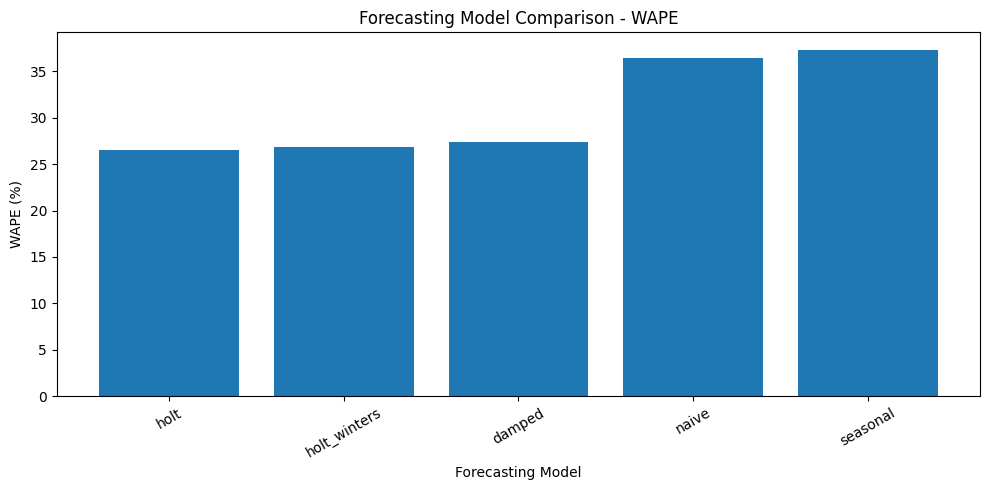

In [ ]:
# Step 1: Visualize overall model performance

import matplotlib.pyplot as plt

model_comparison = model_comparison.sort_values("WAPE (%)")

plt.figure(figsize=(10, 5))
plt.bar(model_comparison["Model"], model_comparison["WAPE (%)"])
plt.title("Forecasting Model Comparison - WAPE")
plt.xlabel("Forecasting Model")
plt.ylabel("WAPE (%)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# Create rolling backtesting windows for SKU-Warehouse level

forecast_horizon = 30
number_of_folds = 4

# Get the complete chronological list of dates
sku_dates = (
    sku_warehouse_daily["date"]
    .drop_duplicates()
    .sort_values()
    .reset_index(drop=True)
)

sku_backtest_windows = []

for fold in range(number_of_folds):

    # Determine the end position of the test period
    test_end = len(sku_dates) - (
        (number_of_folds - 1 - fold) * forecast_horizon
    )

    # Test period starts 30 days before test_end
    test_start = test_end - forecast_horizon

    # Training ends immediately before the test period
    train_end = test_start

    sku_backtest_windows.append({
        "fold": fold + 1,
        "train_start": sku_dates.iloc[0],
        "train_end": sku_dates.iloc[train_end - 1],
        "test_start": sku_dates.iloc[test_start],
        "test_end": sku_dates.iloc[test_end - 1]
    })

sku_backtest_windows_df = pd.DataFrame(
    sku_backtest_windows
)

sku_backtest_windows_df

,fold,train_start,train_end,test_start,test_end
0,1,2024-01-01,2024-09-01,2024-09-02,2024-10-01
1,2,2024-01-01,2024-10-01,2024-10-02,2024-10-31
2,3,2024-01-01,2024-10-31,2024-11-01,2024-11-30
3,4,2024-01-01,2024-11-30,2024-12-01,2024-12-30


In [ ]:
# Step 2A: Prepare training and validation data for each SKU-Warehouse rolling fold

# Make sure the data is sorted chronologically
sku_warehouse_daily = sku_warehouse_daily.sort_values(
    ["sku_id", "warehouse_id", "date"]
).copy()

# Create a list to store the data for all SKU-Warehouse folds
sku_rolling_backtest_data = []

# Loop through each rolling backtest window
for _, window in sku_backtest_windows_df.iterrows():

    # Get the current fold number
    sku_fold = window["fold"]

    # Get training and validation dates
    sku_train_start = window["train_start"]
    sku_train_end = window["train_end"]
    sku_test_start = window["test_start"]
    sku_test_end = window["test_end"]

    # Select training data for this fold
    sku_train_fold = sku_warehouse_daily[
        (sku_warehouse_daily["date"] >= sku_train_start) &
        (sku_warehouse_daily["date"] <= sku_train_end)
    ].copy()

    # Select validation/test data for this fold
    sku_test_fold = sku_warehouse_daily[
        (sku_warehouse_daily["date"] >= sku_test_start) &
        (sku_warehouse_daily["date"] <= sku_test_end)
    ].copy()

    # Add the fold number to both datasets
    sku_train_fold["fold"] = sku_fold
    sku_test_fold["fold"] = sku_fold

    # Store both datasets
    sku_rolling_backtest_data.append({
        "fold": sku_fold,
        "train": sku_train_fold,
        "test": sku_test_fold
    })

# Display basic information for each fold
for sku_fold_data in sku_rolling_backtest_data:

    print(
        f"Fold {sku_fold_data['fold']}: "
        f"Training rows = {len(sku_fold_data['train'])}, "
        f"Validation rows = {len(sku_fold_data['test'])}"
    )

Fold 1: Training rows = 61250, Validation rows = 7500
Fold 2: Training rows = 68750, Validation rows = 7500
Fold 3: Training rows = 76250, Validation rows = 7500
Fold 4: Training rows = 83750, Validation rows = 7500


In [ ]:
# Step 2B: Generate rolling forecasts for all SKU-Warehouse combinations

from statsmodels.tsa.holtwinters import Holt, ExponentialSmoothing
import numpy as np
import pandas as pd

# Store all rolling forecast results
sku_rolling_forecast_results = []

# Loop through each rolling backtest fold
for sku_fold_data in sku_rolling_backtest_data:

    # Get fold information
    current_fold = sku_fold_data["fold"]
    sku_rolling_train = sku_fold_data["train"]
    sku_rolling_test = sku_fold_data["test"]

    # Process each SKU-Warehouse combination
    for (sku, warehouse), sku_train_group in sku_rolling_train.groupby(
        ["sku_id", "warehouse_id"]
    ):

        # Sort training data chronologically
        sku_train_group = sku_train_group.sort_values("date")

        # Get matching validation data
        sku_test_group = sku_rolling_test[
            (sku_rolling_test["sku_id"] == sku) &
            (sku_rolling_test["warehouse_id"] == warehouse)
        ].sort_values("date")

        # Skip if either training or validation data is missing
        if sku_train_group.empty or sku_test_group.empty:
            continue

        # Actual demand during the validation period
        actual_demand = sku_test_group["daily_demand"].astype(float).to_numpy()

        # --------------------------------------------------
        # 1. Naive Forecast
        # --------------------------------------------------

        naive_forecast = np.repeat(
            sku_train_group["daily_demand"].iloc[-1],
            len(sku_test_group)
        )

        # --------------------------------------------------
        # 2. Seasonal Naive Forecast
        # --------------------------------------------------

        last_7_days = (
            sku_train_group["daily_demand"]
            .tail(7)
            .to_numpy()
        )

        seasonal_naive_forecast = np.tile(
            last_7_days,
            int(np.ceil(len(sku_test_group) / 7))
        )[:len(sku_test_group)]

        # --------------------------------------------------
        # 3. Holt Forecast
        # --------------------------------------------------

        holt_model = Holt(
            sku_train_group["daily_demand"].astype(float).to_numpy(),
            initialization_method="estimated"
        ).fit(optimized=True)

        holt_forecast = np.asarray(
            holt_model.forecast(len(sku_test_group))
        )

        # --------------------------------------------------
        # 4. Damped Holt Forecast
        # --------------------------------------------------

        damped_holt_model = Holt(
            sku_train_group["daily_demand"].astype(float).to_numpy(),
            damped_trend=True,
            initialization_method="estimated"
        ).fit(optimized=True)

        damped_holt_forecast = np.asarray(
            damped_holt_model.forecast(len(sku_test_group))
        )

        # --------------------------------------------------
        # 5. Holt-Winters Forecast
        # --------------------------------------------------

        holt_winters_model = ExponentialSmoothing(
            sku_train_group["daily_demand"].astype(float).to_numpy(),
            trend="add",
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated"
        ).fit(optimized=True)

        holt_winters_forecast = np.asarray(
            holt_winters_model.forecast(len(sku_test_group))
        )

        # --------------------------------------------------
        # Store forecasts for all five models
        # --------------------------------------------------

        model_forecasts = {
            "Naive": naive_forecast,
            "Seasonal Naive": seasonal_naive_forecast,
            "Holt": holt_forecast,
            "Damped Holt": damped_holt_forecast,
            "Holt-Winters": holt_winters_forecast
        }

        # Create one result table for each model
        for model_name, forecast_values in model_forecasts.items():

            forecast_result = sku_test_group[
                [
                    "date",
                    "sku_id",
                    "warehouse_id",
                    "daily_demand"
                ]
            ].copy()

            forecast_result["fold"] = current_fold
            forecast_result["model"] = model_name
            forecast_result["forecast"] = forecast_values

            sku_rolling_forecast_results.append(
                forecast_result
            )

# Combine all forecast results
sku_rolling_forecasts = pd.concat(
    sku_rolling_forecast_results,
    ignore_index=True
)

# Sort the final result
sku_rolling_forecasts = sku_rolling_forecasts.sort_values(
    [
        "fold",
        "sku_id",
        "warehouse_id",
        "model",
        "date"
    ]
).reset_index(drop=True)

# Display basic validation information
print(
    "Total forecast rows:",
    len(sku_rolling_forecasts)
)

print(
    "Unique SKU-Warehouse combinations:",
    sku_rolling_forecasts.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

print(
    "Unique folds:",
    sku_rolling_forecasts["fold"].nunique()
)

print(
    "Unique models:",
    sku_rolling_forecasts["model"].nunique()
)

# Preview the results
sku_rolling_forecasts.head(20)

Total forecast rows: 150000
Unique SKU-Warehouse combinations: 250
Unique folds: 4
Unique models: 5


,date,sku_id,warehouse_id,daily_demand,fold,model,forecast
0,2024-09-02,SKU_1,WH_1,8,1,Damped Holt,11.979338
1,2024-09-03,SKU_1,WH_1,9,1,Damped Holt,11.882755
2,2024-09-04,SKU_1,WH_1,4,1,Damped Holt,11.787148
3,2024-09-05,SKU_1,WH_1,5,1,Damped Holt,11.692507
4,2024-09-06,SKU_1,WH_1,17,1,Damped Holt,11.598823
5,2024-09-07,SKU_1,WH_1,8,1,Damped Holt,11.506085
6,2024-09-08,SKU_1,WH_1,4,1,Damped Holt,11.414285
7,2024-09-09,SKU_1,WH_1,11,1,Damped Holt,11.323413
8,2024-09-10,SKU_1,WH_1,17,1,Damped Holt,11.233459
9,2024-09-11,SKU_1,WH_1,7,1,Damped Holt,11.144414


In [ ]:
# Step 3: Calculate MAE, RMSE and WAPE for each
# SKU-Warehouse, fold and forecasting model

from sklearn.metrics import mean_absolute_error, mean_squared_error

# Create a list to store accuracy results
sku_rolling_accuracy_results = []

# Group the forecast results by SKU-Warehouse, fold and model
for (
    (sku, warehouse, fold, model),
    group
) in sku_rolling_forecasts.groupby(
    ["sku_id", "warehouse_id", "fold", "model"]
):

    # Get actual and forecast demand
    actual = group["daily_demand"].astype(float).to_numpy()
    forecast = group["forecast"].astype(float).to_numpy()

    # Calculate MAE
    mae = mean_absolute_error(
        actual,
        forecast
    )

    # Calculate RMSE
    rmse = np.sqrt(
        mean_squared_error(
            actual,
            forecast
        )
    )

    # Calculate WAPE
    total_actual_demand = np.sum(
        np.abs(actual)
    )

    if total_actual_demand == 0:
        wape = np.nan
    else:
        wape = (
            np.sum(np.abs(actual - forecast))
            / total_actual_demand
        ) * 100

    # Store the accuracy result
    sku_rolling_accuracy_results.append({
        "sku_id": sku,
        "warehouse_id": warehouse,
        "fold": fold,
        "model": model,
        "MAE": mae,
        "RMSE": rmse,
        "WAPE (%)": wape
    })

# Combine all accuracy results into one DataFrame
sku_rolling_accuracy = pd.DataFrame(
    sku_rolling_accuracy_results
)

# Sort the results for easier analysis
sku_rolling_accuracy = sku_rolling_accuracy.sort_values(
    [
        "sku_id",
        "warehouse_id",
        "fold",
        "WAPE (%)"
    ]
).reset_index(drop=True)

# Display validation information
print(
    "Total accuracy rows:",
    len(sku_rolling_accuracy)
)

print(
    "Unique SKU-Warehouse combinations:",
    sku_rolling_accuracy.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

print(
    "Unique folds:",
    sku_rolling_accuracy["fold"].nunique()
)

print(
    "Unique models:",
    sku_rolling_accuracy["model"].nunique()
)

# Display the first 20 results
sku_rolling_accuracy.head(20)

Total accuracy rows: 5000
Unique SKU-Warehouse combinations: 250
Unique folds: 4
Unique models: 5


,sku_id,warehouse_id,fold,model,MAE,RMSE,WAPE (%)
0,SKU_1,WH_1,1,Holt-Winters,3.774967,4.718708,38.003021
1,SKU_1,WH_1,1,Holt,3.806578,4.861820,38.321258
2,SKU_1,WH_1,1,Damped Holt,3.874338,4.813589,39.003406
3,SKU_1,WH_1,1,Naive,7.400000,8.406347,74.496644
4,SKU_1,WH_1,1,Seasonal Naive,7.566667,9.239408,76.174497
5,SKU_1,WH_1,2,Seasonal Naive,3.600000,4.753946,33.128834
6,SKU_1,WH_1,2,Naive,3.733333,4.669047,34.355828
7,SKU_1,WH_1,2,Damped Holt,3.777798,4.764220,34.765011
8,SKU_1,WH_1,2,Holt,4.159041,5.156400,38.273381
9,SKU_1,WH_1,2,Holt-Winters,4.297737,5.408899,39.549727


In [ ]:
# Step 4: Calculate average rolling backtest performance
# across the four folds for each SKU-Warehouse and model

sku_rolling_model_performance = (
    sku_rolling_accuracy
    .groupby(
        [
            "sku_id",
            "warehouse_id",
            "model"
        ]
    )
    .agg(
        average_mae=("MAE", "mean"),
        average_rmse=("RMSE", "mean"),
        average_wape=("WAPE (%)", "mean")
    )
    .reset_index()
)

# Round accuracy metrics for readability
sku_rolling_model_performance[
    [
        "average_mae",
        "average_rmse",
        "average_wape"
    ]
] = (
    sku_rolling_model_performance[
        [
            "average_mae",
            "average_rmse",
            "average_wape"
        ]
    ].round(2)
)

# Sort by SKU, Warehouse and WAPE
sku_rolling_model_performance = (
    sku_rolling_model_performance
    .sort_values(
        [
            "sku_id",
            "warehouse_id",
            "average_wape"
        ]
    )
    .reset_index(drop=True)
)

# Display validation information
print(
    "Total performance rows:",
    len(sku_rolling_model_performance)
)

print(
    "Unique SKU-Warehouse combinations:",
    sku_rolling_model_performance.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

print(
    "Unique models:",
    sku_rolling_model_performance["model"].nunique()
)

# Preview the results
sku_rolling_model_performance.head(20)

Total performance rows: 1250
Unique SKU-Warehouse combinations: 250
Unique models: 5


,sku_id,warehouse_id,model,average_mae,average_rmse,average_wape
0,SKU_1,WH_1,Damped Holt,4.44,5.38,34.32
1,SKU_1,WH_1,Holt,4.50,5.48,34.87
2,SKU_1,WH_1,Holt-Winters,4.55,5.52,35.29
3,SKU_1,WH_1,Seasonal Naive,5.43,6.80,43.71
4,SKU_1,WH_1,Naive,7.26,8.20,54.40
5,SKU_1,WH_2,Damped Holt,5.01,6.09,40.69
6,SKU_1,WH_2,Holt,5.13,6.33,41.98
7,SKU_1,WH_2,Holt-Winters,5.25,6.44,43.15
8,SKU_1,WH_2,Naive,6.60,7.78,51.87
9,SKU_1,WH_2,Seasonal Naive,7.33,8.45,56.41


In [ ]:
# Step 5: Select the best forecasting model for each SKU-Warehouse

# Sort by the primary metric (WAPE)
# and use MAE and RMSE as tie-breakers
sku_best_models = (
    sku_rolling_model_performance
    .sort_values(
        [
            "sku_id",
            "warehouse_id",
            "average_wape",
            "average_mae",
            "average_rmse"
        ]
    )
    .drop_duplicates(
        subset=["sku_id", "warehouse_id"],
        keep="first"
    )
    .reset_index(drop=True)
)

# Add ranking for easier interpretation
sku_best_models["model_rank"] = 1

# Sort the final best-model table
sku_best_models = sku_best_models.sort_values(
    ["sku_id", "warehouse_id"]
).reset_index(drop=True)

# Display validation information
print(
    "Total best-model rows:",
    len(sku_best_models)
)

print(
    "Unique SKU-Warehouse combinations:",
    sku_best_models.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

# Display how many SKU-Warehouse combinations
# selected each forecasting model
print("\nBest model distribution:")

print(
    sku_best_models["model"]
    .value_counts()
)

# Preview the selected models
sku_best_models.head(20)

Total best-model rows: 250
Unique SKU-Warehouse combinations: 250

Best model distribution:
model
Damped Holt     195
Holt             24
Naive            18
Holt-Winters     13
Name: count, dtype: int64


,sku_id,warehouse_id,model,average_mae,average_rmse,average_wape,model_rank
0,SKU_1,WH_1,Damped Holt,4.44,5.38,34.32,1
1,SKU_1,WH_2,Damped Holt,5.01,6.09,40.69,1
2,SKU_1,WH_3,Damped Holt,5.21,6.23,42.93,1
3,SKU_1,WH_4,Damped Holt,4.07,5.27,31.28,1
4,SKU_1,WH_5,Holt-Winters,4.65,5.69,36.16,1
5,SKU_10,WH_1,Damped Holt,4.74,5.81,38.47,1
6,SKU_10,WH_2,Damped Holt,4.09,5.09,37.19,1
7,SKU_10,WH_3,Damped Holt,5.06,6.13,41.04,1
8,SKU_10,WH_4,Damped Holt,5.07,6.15,41.42,1
9,SKU_10,WH_5,Damped Holt,4.60,5.67,37.04,1


In [ ]:
# Step 6: Train the selected model on the full historical data
# and generate the final 30-day forecast

# Store the final forecast results
sku_30day_forecast_results = []

# Get the last historical date
last_historical_date = sku_warehouse_daily["date"].max()

# Create the next 30 forecast dates
future_forecast_dates = pd.date_range(
    start=last_historical_date + pd.Timedelta(days=1),
    periods=30,
    freq="D"
)

# Process each SKU-Warehouse combination
for _, best_model_row in sku_best_models.iterrows():

    # Get SKU, Warehouse and selected model
    sku = best_model_row["sku_id"]
    warehouse = best_model_row["warehouse_id"]
    selected_model = best_model_row["model"]

    # Get complete historical demand for this SKU-Warehouse
    historical_group = sku_warehouse_daily[
        (sku_warehouse_daily["sku_id"] == sku) &
        (sku_warehouse_daily["warehouse_id"] == warehouse)
    ].sort_values("date")

    # Extract historical demand values
    historical_demand = (
        historical_group["daily_demand"]
        .astype(float)
        .to_numpy()
    )

    # Generate forecast based on the selected model
    if selected_model == "Naive":

        forecast_values = np.repeat(
            historical_demand[-1],
            30
        )

    elif selected_model == "Seasonal Naive":

        last_7_days = historical_demand[-7:]

        forecast_values = np.tile(
            last_7_days,
            int(np.ceil(30 / 7))
        )[:30]

    elif selected_model == "Holt":

        model = Holt(
            historical_demand,
            initialization_method="estimated"
        ).fit(optimized=True)

        forecast_values = np.asarray(
            model.forecast(30)
        )

    elif selected_model == "Damped Holt":

        model = Holt(
            historical_demand,
            damped_trend=True,
            initialization_method="estimated"
        ).fit(optimized=True)

        forecast_values = np.asarray(
            model.forecast(30)
        )

    elif selected_model == "Holt-Winters":

        model = ExponentialSmoothing(
            historical_demand,
            trend="add",
            seasonal="add",
            seasonal_periods=7,
            initialization_method="estimated"
        ).fit(optimized=True)

        forecast_values = np.asarray(
            model.forecast(30)
        )

    # Create the final forecast table
    forecast_result = pd.DataFrame({
        "date": future_forecast_dates,
        "sku_id": sku,
        "warehouse_id": warehouse,
        "model": selected_model,
        "forecast_demand": forecast_values
    })

    # Add forecast day number
    forecast_result["forecast_day"] = range(1, 31)

    # Store the result
    sku_30day_forecast_results.append(
        forecast_result
    )

# Combine all SKU-Warehouse forecasts
sku_30day_forecast = pd.concat(
    sku_30day_forecast_results,
    ignore_index=True
)

# Sort the final forecast table
sku_30day_forecast = sku_30day_forecast.sort_values(
    [
        "date",
        "sku_id",
        "warehouse_id"
    ]
).reset_index(drop=True)

# Display validation information
print(
    "Total forecast rows:",
    len(sku_30day_forecast)
)

print(
    "Unique SKU-Warehouse combinations:",
    sku_30day_forecast.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

print(
    "Forecast days:",
    sku_30day_forecast["forecast_day"].nunique()
)

print(
    "Forecast date range:",
    sku_30day_forecast["date"].min(),
    "to",
    sku_30day_forecast["date"].max()
)

# Preview the final 30-day forecast
sku_30day_forecast.head(20)

Total forecast rows: 7500
Unique SKU-Warehouse combinations: 250
Forecast days: 30
Forecast date range: 2024-12-31 00:00:00 to 2025-01-29 00:00:00


,date,sku_id,warehouse_id,model,forecast_demand,forecast_day
0,2024-12-31,SKU_1,WH_1,Damped Holt,17.440166,1
1,2024-12-31,SKU_1,WH_2,Damped Holt,18.596052,1
2,2024-12-31,SKU_1,WH_3,Damped Holt,19.357824,1
3,2024-12-31,SKU_1,WH_4,Damped Holt,20.534227,1
4,2024-12-31,SKU_1,WH_5,Holt-Winters,20.865872,1
5,2024-12-31,SKU_10,WH_1,Damped Holt,17.739028,1
6,2024-12-31,SKU_10,WH_2,Damped Holt,19.342023,1
7,2024-12-31,SKU_10,WH_3,Damped Holt,20.970914,1
8,2024-12-31,SKU_10,WH_4,Damped Holt,19.853066,1
9,2024-12-31,SKU_10,WH_5,Damped Holt,21.170796,1


In [ ]:
# Step 7: Validate and summarize the final 30-day forecast

# --------------------------------------------------
# 1. Overall forecast summary
# --------------------------------------------------

overall_forecast_summary = pd.DataFrame({
    "Metric": [
        "Total Forecast Demand",
        "Average Daily Forecast Demand",
        "Minimum Daily Forecast",
        "Maximum Daily Forecast"
    ],
    "Value": [
        sku_30day_forecast["forecast_demand"].sum(),
        sku_30day_forecast["forecast_demand"].mean(),
        sku_30day_forecast["forecast_demand"].min(),
        sku_30day_forecast["forecast_demand"].max()
    ]
})

overall_forecast_summary["Value"] = (
    overall_forecast_summary["Value"].round(2)
)

print("Overall 30-Day Forecast Summary")
display(overall_forecast_summary)


# --------------------------------------------------
# 2. Daily forecast summary
# --------------------------------------------------

daily_forecast_summary = (
    sku_30day_forecast
    .groupby("date")
    .agg(
        total_forecast_demand=("forecast_demand", "sum"),
        average_forecast_demand=("forecast_demand", "mean"),
        sku_warehouse_count=("forecast_demand", "count")
    )
    .reset_index()
)

daily_forecast_summary[
    [
        "total_forecast_demand",
        "average_forecast_demand"
    ]
] = (
    daily_forecast_summary[
        [
            "total_forecast_demand",
            "average_forecast_demand"
        ]
    ].round(2)
)

print("\nDaily Forecast Summary")
display(daily_forecast_summary.head(10))


# --------------------------------------------------
# 3. Forecast by warehouse
# --------------------------------------------------

warehouse_forecast_summary = (
    sku_30day_forecast
    .groupby("warehouse_id")
    .agg(
        total_forecast_demand=("forecast_demand", "sum"),
        average_daily_demand=("forecast_demand", "mean"),
        sku_count=("sku_id", "nunique")
    )
    .reset_index()
)

warehouse_forecast_summary[
    [
        "total_forecast_demand",
        "average_daily_demand"
    ]
] = (
    warehouse_forecast_summary[
        [
            "total_forecast_demand",
            "average_daily_demand"
        ]
    ].round(2)
)

warehouse_forecast_summary = (
    warehouse_forecast_summary
    .sort_values(
        "total_forecast_demand",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nForecast by Warehouse")
display(warehouse_forecast_summary)


# --------------------------------------------------
# 4. Forecast by SKU
# --------------------------------------------------

sku_forecast_summary = (
    sku_30day_forecast
    .groupby("sku_id")
    .agg(
        total_forecast_demand=("forecast_demand", "sum"),
        average_daily_demand=("forecast_demand", "mean"),
        warehouse_count=("warehouse_id", "nunique")
    )
    .reset_index()
)

sku_forecast_summary[
    [
        "total_forecast_demand",
        "average_daily_demand"
    ]
] = (
    sku_forecast_summary[
        [
            "total_forecast_demand",
            "average_daily_demand"
        ]
    ].round(2)
)

sku_forecast_summary = (
    sku_forecast_summary
    .sort_values(
        "total_forecast_demand",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\nTop 10 SKUs by 30-Day Forecast Demand")
display(
    sku_forecast_summary.head(10)
)


# --------------------------------------------------
# 5. Final model distribution
# --------------------------------------------------

final_model_distribution = (
    sku_best_models["model"]
    .value_counts()
    .reset_index()
)

final_model_distribution.columns = [
    "model",
    "sku_warehouse_count"
]

print("\nFinal Selected Model Distribution")
display(final_model_distribution)


# --------------------------------------------------
# 6. Forecast quality checks
# --------------------------------------------------

print("\nForecast Quality Checks")

print(
    "Missing forecast values:",
    sku_30day_forecast["forecast_demand"].isna().sum()
)

print(
    "Negative forecast values:",
    (
        sku_30day_forecast["forecast_demand"] < 0
    ).sum()
)

print(
    "Expected rows:",
    250 * 30
)

print(
    "Actual rows:",
    len(sku_30day_forecast)
)

Overall 30-Day Forecast Summary


,Metric,Value
0,Total Forecast Demand,159457.40
1,Average Daily Forecast Demand,21.26
2,Minimum Daily Forecast,13.79
3,Maximum Daily Forecast,34.78



Daily Forecast Summary


,date,total_forecast_demand,average_forecast_demand,sku_warehouse_count
0,2024-12-31,4905.76,19.62,250
1,2025-01-01,4933.82,19.74,250
2,2025-01-02,4965.06,19.86,250
3,2025-01-03,4996.20,19.98,250
4,2025-01-04,5026.24,20.10,250
5,2025-01-05,5058.31,20.23,250
6,2025-01-06,5088.65,20.35,250
7,2025-01-07,5116.97,20.47,250
8,2025-01-08,5142.74,20.57,250
9,2025-01-09,5171.75,20.69,250



Forecast by Warehouse


...


Top 10 SKUs by 30-Day Forecast Demand


,sku_id,total_forecast_demand,average_daily_demand,warehouse_count
0,SKU_48,3671.15,24.47,5
1,SKU_12,3507.20,23.38,5
2,SKU_37,3494.53,23.30,5
3,SKU_36,3476.66,23.18,5
4,SKU_17,3471.87,23.15,5
5,SKU_40,3443.99,22.96,5
6,SKU_21,3361.86,22.41,5
7,SKU_50,3316.83,22.11,5
8,SKU_47,3305.24,22.03,5
9,SKU_4,3300.67,22.00,5



Final Selected Model Distribution


,model,sku_warehouse_count
0,Damped Holt,195
1,Holt,24
2,Naive,18
3,Holt-Winters,13



Forecast Quality Checks
Missing forecast values: 0
Negative forecast values: 0
Expected rows: 7500
Actual rows: 7500


In [ ]:
# Step 8: Create the final enriched 30-day forecast dataset
# for analysis and Power BI

# --------------------------------------------------
# 1. Select relevant model-performance columns
# --------------------------------------------------

sku_model_selection_details = sku_best_models[
    [
        "sku_id",
        "warehouse_id",
        "model",
        "average_mae",
        "average_rmse",
        "average_wape"
    ]
].copy()


# --------------------------------------------------
# 2. Merge model performance with the 30-day forecast
# --------------------------------------------------

sku_final_forecast_analysis = sku_30day_forecast.merge(
    sku_model_selection_details,
    on=[
        "sku_id",
        "warehouse_id",
        "model"
    ],
    how="left"
)


# --------------------------------------------------
# 3. Calculate total forecast by SKU-Warehouse
# --------------------------------------------------

sku_warehouse_forecast_totals = (
    sku_final_forecast_analysis
    .groupby(
        [
            "sku_id",
            "warehouse_id"
        ]
    )["forecast_demand"]
    .transform("sum")
)

sku_final_forecast_analysis[
    "sku_warehouse_30day_total"
] = sku_warehouse_forecast_totals


# --------------------------------------------------
# 4. Calculate each SKU-Warehouse share of
#    total network forecast
# --------------------------------------------------

total_network_forecast = (
    sku_final_forecast_analysis["forecast_demand"].sum()
)

sku_final_forecast_analysis[
    "forecast_share_pct"
] = (
    sku_final_forecast_analysis[
        "sku_warehouse_30day_total"
    ]
    / total_network_forecast
) * 100


# --------------------------------------------------
# 5. Round numerical columns
# --------------------------------------------------

sku_final_forecast_analysis[
    [
        "forecast_demand",
        "average_mae",
        "average_rmse",
        "average_wape",
        "sku_warehouse_30day_total",
        "forecast_share_pct"
    ]
] = (
    sku_final_forecast_analysis[
        [
            "forecast_demand",
            "average_mae",
            "average_rmse",
            "average_wape",
            "sku_warehouse_30day_total",
            "forecast_share_pct"
        ]
    ].round(2)
)


# --------------------------------------------------
# 6. Sort the final analysis dataset
# --------------------------------------------------

sku_final_forecast_analysis = (
    sku_final_forecast_analysis
    .sort_values(
        [
            "date",
            "sku_id",
            "warehouse_id"
        ]
    )
    .reset_index(drop=True)
)


# --------------------------------------------------
# 7. Validation checks
# --------------------------------------------------

print(
    "Total final analysis rows:",
    len(sku_final_forecast_analysis)
)

print(
    "Unique SKU-Warehouse combinations:",
    sku_final_forecast_analysis.groupby(
        ["sku_id", "warehouse_id"]
    ).ngroups
)

print(
    "Forecast dates:",
    sku_final_forecast_analysis["date"].nunique()
)

print(
    "Missing model performance values:",
    sku_final_forecast_analysis[
        [
            "average_mae",
            "average_rmse",
            "average_wape"
        ]
    ].isna().sum().sum()
)

print(
    "Total network forecast:",
    sku_final_forecast_analysis[
        "forecast_demand"
    ].sum().round(2)
)


# --------------------------------------------------
# 8. Preview final dataset
# --------------------------------------------------

sku_final_forecast_analysis.tail(30)

Total final analysis rows: 7500
Unique SKU-Warehouse combinations: 250
Forecast dates: 30
Missing model performance values: 0
Total network forecast: 159457.44


,date,sku_id,warehouse_id,model,forecast_demand,forecast_day,average_mae,average_rmse,average_wape,sku_warehouse_30day_total,forecast_share_pct
7470,2025-01-29,SKU_5,WH_1,Damped Holt,21.17,30,4.49,5.63,36.43,593.09,0.37
7471,2025-01-29,SKU_5,WH_2,Naive,19.00,30,4.85,6.24,39.89,570.00,0.36
7472,2025-01-29,SKU_5,WH_3,Damped Holt,21.04,30,4.36,5.47,37.91,595.85,0.37
7473,2025-01-29,SKU_5,WH_4,Damped Holt,20.05,30,3.99,5.01,31.38,556.46,0.35
7474,2025-01-29,SKU_5,WH_5,Damped Holt,22.98,30,4.20,5.18,32.43,653.26,0.41
7475,2025-01-29,SKU_50,WH_1,Holt-Winters,26.48,30,4.40,5.73,38.96,730.23,0.46
7476,2025-01-29,SKU_50,WH_2,Damped Holt,24.18,30,4.78,5.83,37.66,688.77,0.43
7477,2025-01-29,SKU_50,WH_3,Damped Holt,21.97,30,4.87,5.95,40.49,619.04,0.39
7478,2025-01-29,SKU_50,WH_4,Holt,25.68,30,4.24,5.18,35.75,689.67,0.43
7479,2025-01-29,SKU_50,WH_5,Holt-Winters,21.26,30,4.04,5.10,35.07,589.13,0.37


In [ ]:
# Export the final 30-day SKU-Warehouse forecast to Excel

output_file = "30_Day_SKU_Warehouse_Forecast.xlsx"

with pd.ExcelWriter(output_file, engine="openpyxl") as writer:
    
    # Main forecast output
    sku_final_forecast_analysis.to_excel(
        writer,
        sheet_name="30_Day_Forecast",
        index=False
    )

print(f"Excel file created successfully: {output_file}")
print(f"Rows exported: {len(sku_final_forecast_analysis):,}")
print(f"Columns exported: {len(sku_final_forecast_analysis.columns)}")

Excel file created successfully: 30_Day_SKU_Warehouse_Forecast.xlsx
Rows exported: 7,500
Columns exported: 11
